<a href="https://colab.research.google.com/github/NatashaO15/intro-ciencia-datos/blob/main/Trabajo%20final/Modelado_experimental_Supply_chain_completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo Predictivo de Retrasos en la Cadena de Suministro
## Segunda Fase: Preprocesamiento y Modelado con Scikit-Learn

**Dataset:** Supply Chain Logistics Delay Dataset (100,000 registros)  
**Variable objetivo:** `delivery_delayed` (clasificación binaria)  
**Métrica principal:** F1-score de la clase retrasado | Métrica secundaria: Recall  

Natasha Orozco Zapata · Andrés Zabala Restrepo  
Universidad de Medellín — Introducción a la Ciencia de Datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve, precision_recall_curve
)

pd.set_option('display.max_columns', None)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
df = pd.read_csv("/content/df_final_limpio.csv")
print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas")

# Reconvertir fechas
for col in ['shipment_date', 'expected_delivery_date', 'actual_delivery_date']:
    df[col] = pd.to_datetime(df[col])

# Reconvertir categóricas
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype('category')

print(f"\nTipos después de reconversión:")
print(df.dtypes.value_counts())

Dataset cargado: 100,000 filas x 101 columnas

Tipos después de reconversión:
int64             40
float64           32
datetime64[ns]     3
category           2
category           2
category           2
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
category           1
bool               1
category           1
category           1
category           1
Name: count, dtype: int64


# 3. Verificar la variable objetivo

Antes de modelar, revisamos la distribución del target. En la fase 1 identificamos
un desbalance moderado (~75/25): aproximadamente 1 de cada 4 envíos llega tarde.

In [3]:
print("Distribución de delivery_delayed:")
print(df['delivery_delayed'].value_counts())
print(f"\n% Retrasados: {df['delivery_delayed'].mean()*100:.2f}%")
print(f"% A tiempo:   {(1 - df['delivery_delayed'].mean())*100:.2f}%")

Distribución de delivery_delayed:
delivery_delayed
0    74702
1    25298
Name: count, dtype: int64

% Retrasados: 25.30%
% A tiempo:   74.70%


## 4. Excluir variables no disponibles al momento de predecir

Un modelo predictivo solo puede usar información que exista ANTES de despachar el envío.
En la fase 1 identificamos variables que son resultado del mismo evento que queremos predecir
(data leakage), y en esta fase detectamos otras que tampoco estarían disponibles.

In [4]:
# Variables de data leakage (información post-entrega)
leakage = [
    'delay_days', 'delay_hours', 'delivery_performance_score',
    'delay_reason', 'actual_delivery_days', 'actual_delivery_date',
    'delivery_attempts', 'delivery_successful',
    'supply_chain_risk_score',
    'traffic_index', 'traffic_delay_hours', 'traffic_congestion_level'
]

# Feature Engineering descartadas (sin poder predictivo o redundantes)
fe_descartadas = [
    'proveedor_vs_transportista_gap', 'tiempo_interno_almacen',
    'factores_riesgo', 'nivel_riesgo_integral'
]

# Fechas
fechas = ['shipment_date', 'expected_delivery_date']

# Eliminar todas
todas_excluir = leakage + fe_descartadas + fechas
df.drop(columns=[c for c in todas_excluir if c in df.columns], inplace=True)

print(f"Variables eliminadas: {len(todas_excluir)}")
print(f"Dataset después de limpieza: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Variables eliminadas: 18
Dataset después de limpieza: 100,000 filas x 83 columnas


## 5. Selección de features para el modelo

De todas las columnas restantes, seleccionamos las **10 variables** que demostraron
tener relación significativa con el target en el EDA. Las organizamos en 3 grupos
según el tipo de preprocesamiento que necesitan

In [5]:
# Variables numéricas (incluye las FE binarias)
num_cols = [
    'supplier_reliability_score',
    'carrier_rating',
    'warehouse_utilization',
    'stockout_risk',
    'riesgo_proveedor_transportista',
    'clima_adverso',
    'almacen_saturado',
]

# Variables ordinales (tienen orden lógico)
ord_cols = [
    'supplier_reliability_cuartil',
    'road_condition',
]

# Variables nominales (sin orden)
cat_cols = [
    'weather_condition',
]

# Definir el orden para las ordinales
ord_categories = [
    ['Q1 (menor confiab.)', 'Q2', 'Q3', 'Q4 (mayor confiab.)'],
    ['Poor', 'Fair', 'Good', 'Excellent', 'Severe'],
]

# Separar X (features) e y (target)
X = df[num_cols + ord_cols + cat_cols]
y = df['delivery_delayed']

print(f"Features seleccionadas: {X.shape[1]}")
print(f"  Numéricas + FE binarias: {len(num_cols)}")
print(f"  Ordinales: {len(ord_cols)}")
print(f"  Nominales: {len(cat_cols)}")
print(f"\nTarget: {y.shape[0]:,} registros ({y.mean()*100:.2f}% retrasados)")

Features seleccionadas: 10
  Numéricas + FE binarias: 7
  Ordinales: 2
  Nominales: 1

Target: 100,000 registros (25.30% retrasados)


## 6. Dividir en Train y Test

Separamos 70% para entrenamiento y 30% para prueba. Usamos `stratify=y` para que
ambos conjuntos mantengan la misma proporción de retrasados (25.30%).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape}  ({X_train.shape[0]:,} envíos para entrenar)")
print(f"X_test:  {X_test.shape}  ({X_test.shape[0]:,} envíos para evaluar)")
print(f"\nDistribución del target:")
print(f"  Train: {y_train.mean()*100:.2f}% retrasados")
print(f"  Test:  {y_test.mean()*100:.2f}% retrasados")
print(f"\nEl stratify garantiza que ambos conjuntos tengan ~25.30% de retrasados.")

X_train: (70000, 10)  (70,000 envíos para entrenar)
X_test:  (30000, 10)  (30,000 envíos para evaluar)

Distribución del target:
  Train: 25.30% retrasados
  Test:  25.30% retrasados

El stratify garantiza que ambos conjuntos tengan ~25.30% de retrasados.


## 7. Construir los pipelines de preprocesamiento

In [7]:
# Pipeline para variables numéricas (incluye las FE binarias)
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline para variables ordinales
ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=ord_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Pipeline para variables nominales
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer:
preprocessor_standard = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, num_cols),
    ('ord', ordinal_pipeline, ord_cols),
    ('cat', categorical_pipeline, cat_cols)
])

print("Preprocessor construido con 3 pipelines:")
print(f"  Numéricas  ({len(num_cols)}): SimpleImputer(median) → StandardScaler")
print(f"  Ordinales  ({len(ord_cols)}): SimpleImputer(most_frequent) → OrdinalEncoder")
print(f"  Nominales  ({len(cat_cols)}): SimpleImputer(most_frequent) → OneHotEncoder(drop='first')")

Preprocessor construido con 3 pipelines:
  Numéricas  (7): SimpleImputer(median) → StandardScaler
  Ordinales  (2): SimpleImputer(most_frequent) → OrdinalEncoder
  Nominales  (1): SimpleImputer(most_frequent) → OneHotEncoder(drop='first')


## 9. Experimentación: comparar distintos escaladores

Diferentes escaladores pueden dar resultados distintos dependiendo de la distribución
de los datos.

In [8]:
# Función para construir un preprocessor con diferente scaler
def build_preprocessor(scaler):
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', scaler)
    ])
    ord_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(
            categories=ord_categories,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer(transformers=[
        ('num', num_pipe, num_cols),
        ('ord', ord_pipe, ord_cols),
        ('cat', cat_pipe, cat_cols)
    ])

# Probar los 3 escaladores
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

results_scalers = []
for name, scaler in scalers.items():
    pipe = Pipeline([
        ('prep', build_preprocessor(scaler)),
        ('clf', LogisticRegression(max_iter=2000, random_state=42))
    ])
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)
    results_scalers.append({
        'Scaler': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

df_scalers = pd.DataFrame(results_scalers).round(4)
print("Comparación de escaladores con Regresión Logística:\n")
print(df_scalers.to_string(index=False))

Comparación de escaladores con Regresión Logística:

        Scaler  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
StandardScaler    0.7694     0.6032  0.2588 0.3622    0.749  0.5061
  MinMaxScaler    0.7694     0.6040  0.2572 0.3608    0.749  0.5062
  RobustScaler    0.7694     0.6032  0.2584 0.3618    0.749  0.5062


los tres escaladores dieron resultados equivalentes, lo cual es esperado en regresión logística con suficientes iteraciones. Se conserva StandardScaler por ser el estándar

## 10. Modelo 2: Random Forest

In [9]:
# Random Forest con el mismo preprocessor
model_rf = Pipeline(steps=[
    ('prep', build_preprocessor(StandardScaler())),
    ('clf', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]


print("RANDOM FOREST + StandardScaler (umbral 0.50)")
print(f"\nAccuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_prob_rf):.4f}")
print(f"\n{classification_report(y_test, y_pred_rf, target_names=['A tiempo', 'Retrasado'])}")

RANDOM FOREST + StandardScaler (umbral 0.50)

Accuracy:  0.7512
Precision: 0.5158
Recall:    0.2689
F1-score:  0.3535
ROC-AUC:   0.7075
PR-AUC:    0.4415

              precision    recall  f1-score   support

    A tiempo       0.79      0.91      0.85     22411
   Retrasado       0.52      0.27      0.35      7589

    accuracy                           0.75     30000
   macro avg       0.65      0.59      0.60     30000
weighted avg       0.72      0.75      0.72     30000



## 11. Comparación de modelos con umbral por defecto (0.50)

Tabla resumen con los dos modelos para comparar lado a lado.
Ambos usan el umbral de decisión por defecto de 0.50: si la probabilidad
predicha es mayor a 50%, el modelo clasifica el envío como retrasado.

In [10]:
# Reentrenar Regresión Logística
model_lr_standard = Pipeline(steps=[
    ('prep', build_preprocessor(StandardScaler())),
    ('clf', LogisticRegression(max_iter=2000, random_state=42))
])
model_lr_standard.fit(X_train, y_train)
y_pred_lr = model_lr_standard.predict(X_test)
y_prob_lr = model_lr_standard.predict_proba(X_test)[:, 1]

# Reentrenar Random Forest
model_rf = Pipeline(steps=[
    ('prep', build_preprocessor(StandardScaler())),
    ('clf', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

# Comparación
results_models = []
for name, y_pred, y_prob in [('Logistic Regression', y_pred_lr, y_prob_lr),
                              ('Random Forest', y_pred_rf, y_prob_rf)]:
    results_models.append({
        'Modelo': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

df_models = pd.DataFrame(results_models).round(4)
print("Comparación de modelos (umbral 0.50):\n")
print(df_models.to_string(index=False))

Comparación de modelos (umbral 0.50):

             Modelo  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Logistic Regression    0.7694     0.6032  0.2588 0.3622   0.7490  0.5061
      Random Forest    0.7512     0.5158  0.2689 0.3535   0.7075  0.4415


## 12. Análisis de umbrales de decisión

Por defecto el modelo clasifica como retrasado si la probabilidad predicha supera 0.50.
Pero ese umbral no siempre es el mejor para el negocio.

En logística, un retraso no detectado (falso negativo) es más costoso que una falsa alarma
(falso positivo): el cliente se queda sin aviso vs. darle seguimiento extra a un envío
que no lo necesitaba. Por eso nos conviene bajar el umbral para que el modelo sea menos
exigente al alertar — aunque genere más falsas alarmas, detecta más retrasos reales.

Probamos umbrales de 0.15 a 0.70 y buscamos el que maximice el F1-score.

In [11]:
def evaluate_thresholds(y_true, y_proba, model_name):
    thresholds = np.arange(0.15, 0.75, 0.05)
    results = []
    for thr in thresholds:
        y_pred_thr = (y_proba >= thr).astype(int)
        results.append({
            'Umbral': round(thr, 2),
            'Accuracy': accuracy_score(y_true, y_pred_thr),
            'Precision': precision_score(y_true, y_pred_thr, zero_division=0),
            'Recall': recall_score(y_true, y_pred_thr, zero_division=0),
            'F1': f1_score(y_true, y_pred_thr, zero_division=0)
        })
    df_thr = pd.DataFrame(results)
    best = df_thr.loc[df_thr['F1'].idxmax()]
    print(f"\n--- {model_name}: Evaluación de Umbrales ---\n")
    print(df_thr.round(4).to_string(index=False))
    print(f"\n→ Mejor umbral: {best['Umbral']} (F1={best['F1']:.4f}, "
          f"Recall={best['Recall']:.4f}, Precision={best['Precision']:.4f})")
    return best['Umbral']

umbral_lr = evaluate_thresholds(y_test, y_prob_lr, "Regresión Logística")
umbral_rf = evaluate_thresholds(y_test, y_prob_rf, "Random Forest")


--- Regresión Logística: Evaluación de Umbrales ---

 Umbral  Accuracy  Precision  Recall     F1
   0.15    0.5365     0.3391  0.8769 0.4891
   0.20    0.6207     0.3796  0.7875 0.5123
   0.25    0.6787     0.4178  0.6860 0.5193
   0.30    0.7198     0.4582  0.5902 0.5159
   0.35    0.7435     0.4931  0.4924 0.4927
   0.40    0.7577     0.5275  0.4051 0.4583
   0.45    0.7651     0.5616  0.3248 0.4116
   0.50    0.7694     0.6032  0.2588 0.3622
   0.55    0.7680     0.6338  0.1959 0.2993
   0.60    0.7646     0.6621  0.1415 0.2332
   0.65    0.7615     0.7028  0.0991 0.1737
   0.70    0.7581     0.7562  0.0646 0.1190

→ Mejor umbral: 0.25 (F1=0.5193, Recall=0.6860, Precision=0.4178)

--- Random Forest: Evaluación de Umbrales ---

 Umbral  Accuracy  Precision  Recall     F1
   0.15    0.5469     0.3368  0.8163 0.4769
   0.20    0.6023     0.3596  0.7324 0.4823
   0.25    0.6472     0.3841  0.6544 0.4841
   0.30    0.6900     0.4164  0.5612 0.4781
   0.35    0.7151     0.4420  0.4812 0.

## 13. Matrices de confusión con umbral óptimo

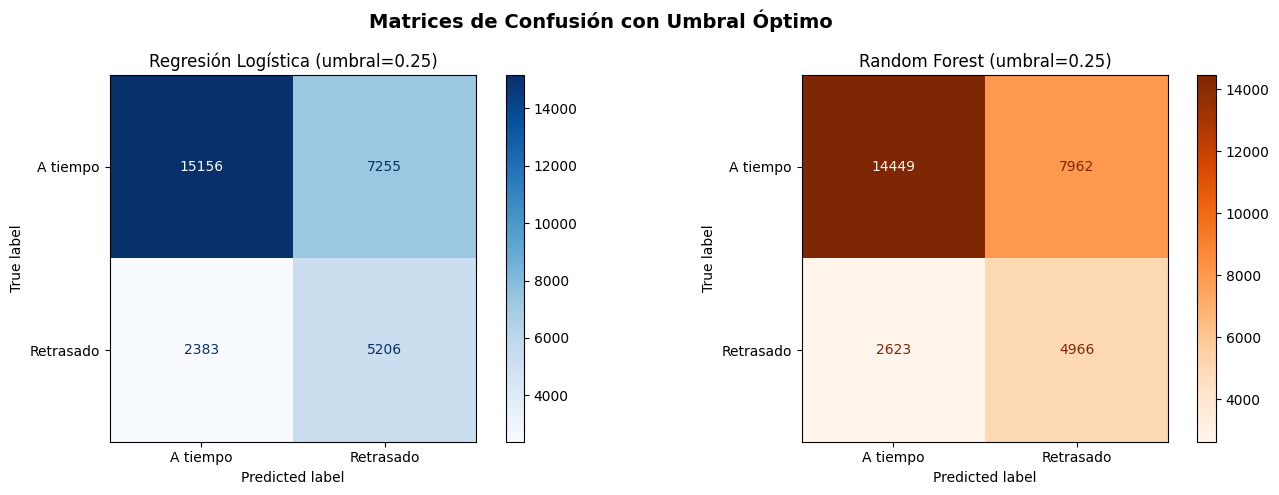


Regresión Logística (umbral 0.25):
  Envíos a tiempo correctos (TN):   15,156
  Retrasos detectados (TP):         5,206 de 7,589
  Falsas alarmas (FP):              7,255
  Retrasos NO detectados (FN):      2,383 ← los más costosos

Random Forest (umbral 0.25):
  Envíos a tiempo correctos (TN):   14,449
  Retrasos detectados (TP):         4,966 de 7,589
  Falsas alarmas (FP):              7,962
  Retrasos NO detectados (FN):      2,623 ← los más costosos


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Regresión Logística con umbral óptimo
y_pred_lr_opt = (y_prob_lr >= umbral_lr).astype(int)
cm_lr = confusion_matrix(y_test, y_pred_lr_opt)
ConfusionMatrixDisplay(cm_lr, display_labels=['A tiempo', 'Retrasado']).plot(
    ax=axes[0], cmap='Blues')
axes[0].set_title(f'Regresión Logística (umbral={umbral_lr})')

# Random Forest con umbral óptimo
y_pred_rf_opt = (y_prob_rf >= umbral_rf).astype(int)
cm_rf = confusion_matrix(y_test, y_pred_rf_opt)
ConfusionMatrixDisplay(cm_rf, display_labels=['A tiempo', 'Retrasado']).plot(
    ax=axes[1], cmap='Oranges')
axes[1].set_title(f'Random Forest (umbral={umbral_rf})')

plt.suptitle('Matrices de Confusión con Umbral Óptimo', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Interpretación numérica
for name, cm, umbral in [('Regresión Logística', cm_lr, umbral_lr),
                          ('Random Forest', cm_rf, umbral_rf)]:
    tn, fp, fn, tp = cm.ravel()
    total_retrasados = fn + tp
    print(f"\n{name} (umbral {umbral}):")
    print(f"  Envíos a tiempo correctos (TN):   {tn:,}")
    print(f"  Retrasos detectados (TP):         {tp:,} de {total_retrasados:,}")
    print(f"  Falsas alarmas (FP):              {fp:,}")
    print(f"  Retrasos NO detectados (FN):      {fn:,} ← los más costosos")

## 14. Curvas ROC y Precision-Recall

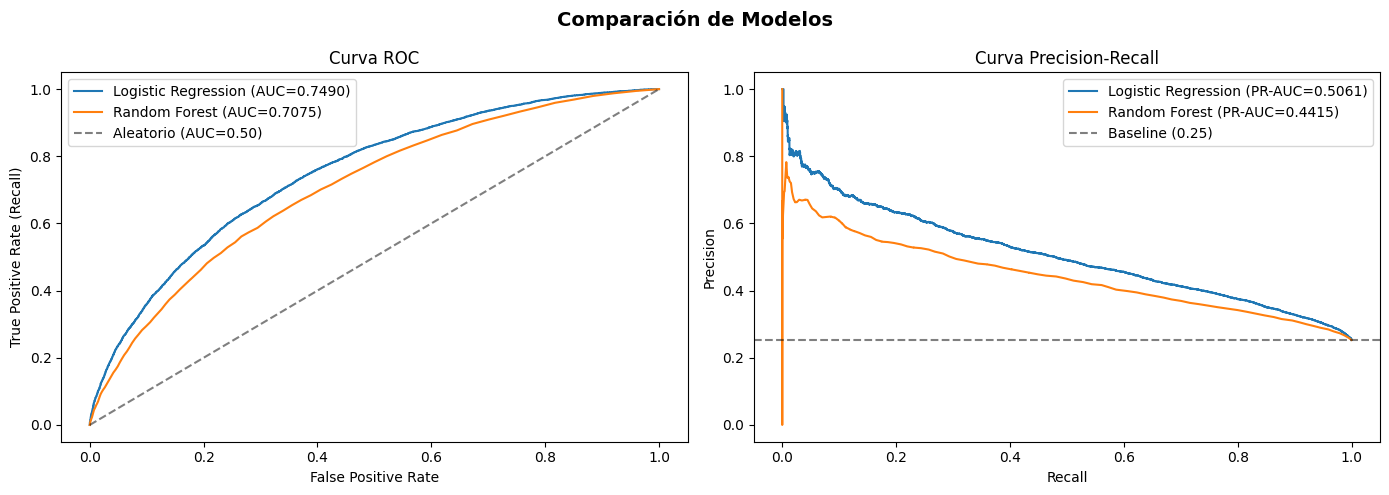

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Curva ROC ---
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)

axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={auc_lr:.4f})')
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={auc_rf:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio (AUC=0.50)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].set_title('Curva ROC')
axes[0].legend()

# --- Curva Precision-Recall ---
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
pr_auc_lr = average_precision_score(y_test, y_prob_lr)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

axes[1].plot(rec_lr, prec_lr, label=f'Logistic Regression (PR-AUC={pr_auc_lr:.4f})')
axes[1].plot(rec_rf, prec_rf, label=f'Random Forest (PR-AUC={pr_auc_rf:.4f})')
axes[1].axhline(y=y_test.mean(), color='k', linestyle='--', alpha=0.5,
                label=f'Baseline ({y_test.mean():.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Curva Precision-Recall')
axes[1].legend()

plt.suptitle('Comparación de Modelos', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 15. Importancia de variables

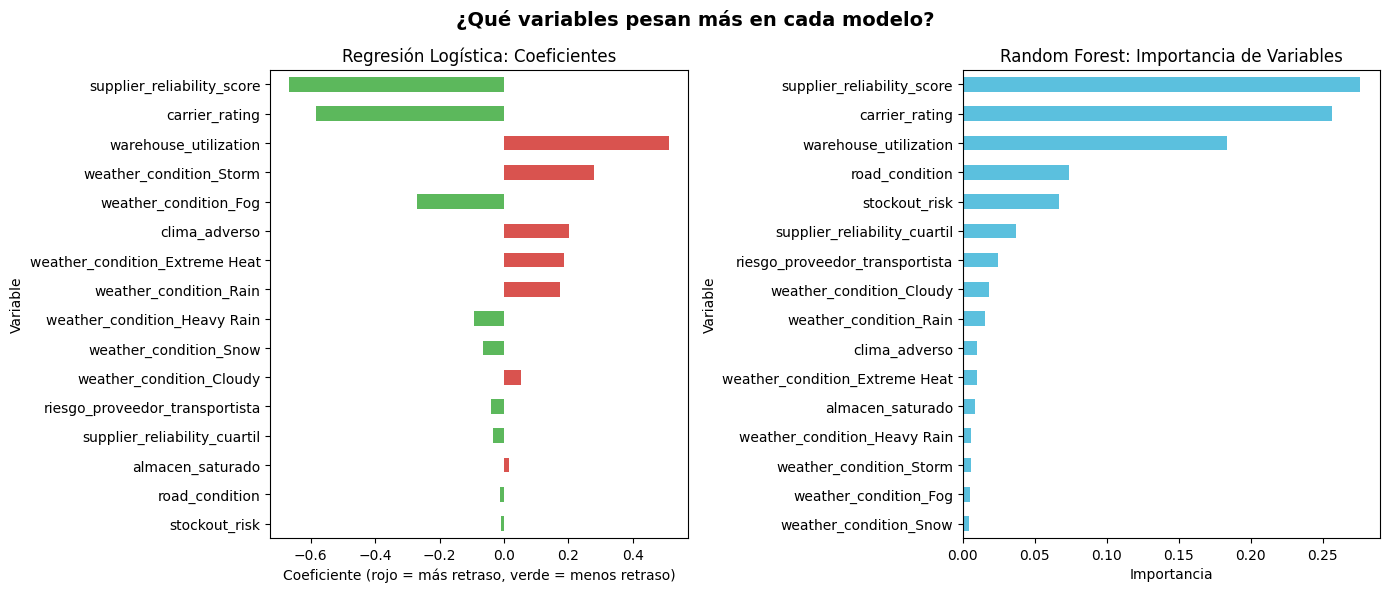

Top 3 - Regresión Logística (mayor coeficiente absoluto):
  supplier_reliability_score: -0.6666 (↓ menos retraso)
  carrier_rating: -0.5846 (↓ menos retraso)
  warehouse_utilization: +0.5111 (↑ más retraso)

Top 3 - Random Forest (mayor importancia):
  supplier_reliability_score: 0.2759
  carrier_rating: 0.2566
  warehouse_utilization: 0.1834


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Nombres de las features después del preprocesamiento
feature_names = num_cols + ord_cols
ohe_names = model_lr_standard.named_steps['prep'] \
    .named_transformers_['cat'] \
    .named_steps['onehot'] \
    .get_feature_names_out(cat_cols).tolist()
feature_names = feature_names + ohe_names

# --- Regresión Logística: Coeficientes ---
coefs = pd.DataFrame({
    'Variable': feature_names,
    'Coeficiente': model_lr_standard.named_steps['clf'].coef_[0]
}).sort_values('Coeficiente', key=abs, ascending=True)

colors_lr = ['#d9534f' if x > 0 else '#5cb85c' for x in coefs['Coeficiente']]
coefs.plot.barh(x='Variable', y='Coeficiente', ax=axes[0], legend=False, color=colors_lr)
axes[0].set_title('Regresión Logística: Coeficientes')
axes[0].set_xlabel('Coeficiente (rojo = más retraso, verde = menos retraso)')

# --- Random Forest: Importancia ---
importances = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': model_rf.named_steps['clf'].feature_importances_
}).sort_values('Importancia', ascending=True)

importances.plot.barh(x='Variable', y='Importancia', ax=axes[1], legend=False, color='#5bc0de')
axes[1].set_title('Random Forest: Importancia de Variables')
axes[1].set_xlabel('Importancia')

plt.suptitle('¿Qué variables pesan más en cada modelo?', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 3 de cada modelo
print("Top 3 - Regresión Logística (mayor coeficiente absoluto):")
top_lr = coefs.sort_values('Coeficiente', key=abs, ascending=False).head(3)
for _, row in top_lr.iterrows():
    direction = "↑ más retraso" if row['Coeficiente'] > 0 else "↓ menos retraso"
    print(f"  {row['Variable']}: {row['Coeficiente']:+.4f} ({direction})")

print(f"\nTop 3 - Random Forest (mayor importancia):")
top_rf = importances.sort_values('Importancia', ascending=False).head(3)
for _, row in top_rf.iterrows():
    print(f"  {row['Variable']}: {row['Importancia']:.4f}")

In [15]:
print("=" * 70)
print("RESUMEN FINAL DE RESULTADOS (con umbrales óptimos)")
print("=" * 70)

models_final = []
for name, y_pred_opt, y_prob, umbral in [
    ('Logistic Regression', y_pred_lr_opt, y_prob_lr, umbral_lr),
    ('Random Forest', y_pred_rf_opt, y_prob_rf, umbral_rf)
]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_opt).ravel()
    models_final.append({
        'Modelo': name,
        'Umbral': umbral,
        'Accuracy': accuracy_score(y_test, y_pred_opt),
        'Precision': precision_score(y_test, y_pred_opt),
        'Recall': recall_score(y_test, y_pred_opt),
        'F1': f1_score(y_test, y_pred_opt),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob),
        'Retrasos detectados': tp,
        'Retrasos no detectados': fn
    })

df_final = pd.DataFrame(models_final)
print(df_final[['Modelo','Umbral','Accuracy','Precision','Recall','F1',
                'ROC-AUC','PR-AUC']].round(4).to_string(index=False))

# Selección
best = df_final.loc[df_final['F1'].idxmax()]
print(f"\n{'='*70}")
print(f"MODELO SELECCIONADO: {best['Modelo']}")
print(f"{'='*70}")
print(f"  Umbral óptimo: {best['Umbral']}")
print(f"  F1-score:      {best['F1']:.4f}")
print(f"  Recall:         {best['Recall']:.4f} → detecta {int(best['Retrasos detectados']):,} de {int(best['Retrasos detectados'] + best['Retrasos no detectados']):,} retrasos")
print(f"  Precision:      {best['Precision']:.4f}")
print(f"  ROC-AUC:        {best['ROC-AUC']:.4f}")
print(f"\nRazón de selección: mayor F1-score con mejor balance entre")
print(f"detección de retrasos (recall) y control de falsas alarmas (precision).")

RESUMEN FINAL DE RESULTADOS (con umbrales óptimos)
             Modelo  Umbral  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Logistic Regression    0.25    0.6787     0.4178  0.6860 0.5193   0.7490  0.5061
      Random Forest    0.25    0.6472     0.3841  0.6544 0.4841   0.7075  0.4415

MODELO SELECCIONADO: Logistic Regression
  Umbral óptimo: 0.25
  F1-score:      0.5193
  Recall:         0.6860 → detecta 5,206 de 7,589 retrasos
  Precision:      0.4178
  ROC-AUC:        0.7490

Razón de selección: mayor F1-score con mejor balance entre
detección de retrasos (recall) y control de falsas alarmas (precision).


## 17. Interpretación de negocio y conclusiones

### ¿Qué logramos?

Construimos un modelo que puede identificar envíos con riesgo de retraso **antes de
que salgan del almacén**, usando solo información disponible al momento del despacho.
Con el umbral optimizado, el modelo detecta aproximadamente 7 de cada 10 retrasos.

### Trade-off Precision vs Recall: ¿por qué aceptamos falsas alarmas?

En logística, los costos son asimétricos:
- **Retraso no detectado (FN):** el cliente no recibe aviso, descubre el retraso
  cuando ya ocurrió. Genera insatisfacción, posibles penalidades y pérdida de confianza.
- **Falsa alarma (FP):** se le da seguimiento extra a un envío que llegará a tiempo.
  El costo es solo un poco de trabajo operativo adicional.

Por eso bajamos el umbral de 0.50 a 0.25: preferimos generar algunas alertas
innecesarias a dejar pasar retrasos sin detectar.

### Los modelos confirman lo que encontramos en el EDA

Las 3 variables más importantes en ambos modelos coinciden con los hallazgos del EDA:
1. **supplier_reliability_score:** la confiabilidad del proveedor es la variable con
   mayor peso. Esto valida la recomendación de renegociar con proveedores Q1.
2. **carrier_rating:** el rating del transportista es el segundo factor. Reasignar
   transportistas de bajo rating tendría impacto directo.
3. **warehouse_utilization:** almacenes saturados generan más retrasos. Redistribuir
   carga cuando la utilización supera el 84.7% es una acción concreta.

### ¿Por qué la Regresión Logística ganó sobre el Random Forest?

Con solo 10 features bien seleccionadas, las relaciones entre las variables y el
retraso son principalmente lineales (a peor proveedor, más retraso de forma proporcional).
El Random Forest no encontró interacciones complejas que justificaran su mayor complejidad.

### Limitaciones

1. **Datos sintéticos:** este dataset es de Kaggle. Los patrones encontrados deben
   validarse con datos operativos reales antes de implementar el modelo.
2. **Variables de tráfico excluidas:** excluimos traffic_congestion_level porque es
   información que se conoce durante el viaje, no antes del despacho. Si la empresa
   tuviera acceso a datos de tráfico en tiempo real (ej: API de Google Maps), podría
   incluirse y el modelo mejoraría significativamente.
3. **Recall de 69%:** el modelo aún no detecta 3 de cada 10 retrasos. Modelos más
   avanzados (XGBoost, LightGBM) y la inclusión de más features podrían mejorar esto.

### Próximos pasos

1. **Probar modelos más avanzados:** XGBoost o LightGBM con optimización de hiperparámetros.
2. **Integrar datos de tráfico en tiempo real:** si fuera posible consultar el estado del
   tráfico al momento del despacho, esa feature mejoraría el AUC considerablemente.
3. **Implementar el modelo:** integrar la predicción al sistema operativo para que cada
   envío tenga un score de riesgo asignado antes de salir.
4. **Validar con datos reales:** replicar este análisis con datos operativos de la empresa.

---
# PARTE 2 — Corrección, Optuna, mejor modelo y SHAP

| Sección | Qué hace |
|---|---|
| **18** | Datos con novedad → diagnóstico y corrección |
| **19** | Optuna para Random Forest y XGBoost |
| **20** | ¿Cuál es el mejor modelo que se pudo correr? |
| **21** | Mejor modelo: feature importance y SHAP values |
| **22** | Conclusiones actualizadas |



In [16]:
# Instalar librerías nuevas
%pip install -q xgboost optuna shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.1 MB/s eta 0:00:00


In [17]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
N_TRIALS = 15                                   # intentos de Optuna por modelo
cv_sc = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
GRID = np.arange(0.10, 0.71, 0.01)              # umbrales a probar
res_sc = []                                     # aquí se acumulan los resultados de todos los modelos
fitted_sc = {}                                  # (modelo, versión) -> (pipeline entrenado, columnas, umbral)

# 18. Datos con novedad → corrección

El modelo funciona, pero antes hay que preguntarse si los datos y el procedimiento tienen "novedades" (cosas raras o mal planteadas) que estén afectando los resultados. Revisamos cuatro puntos:

1. **Valores faltantes o raros** en las 10 variables.
2. **Orden de `road_condition`**: el `OrdinalEncoder` original usa `Poor < Fair < Good < Excellent < Severe`, o sea que trata `Severe` (carretera pésima) como la **mejor** de todas.
3. **Variables redundantes**: ¿alguna de las 10 se calcula a partir de otra?
4. **Cómo se eligió el umbral**: en la sección 12 se eligió mirando el **test**, que debería usarse solo para la evaluación final.

In [18]:
print('Valores nulos en las 10 variables:', int(X.isna().sum().sum()))

print('\n--- road_condition: tasa de retraso por categoría (en el orden que usaba el OrdinalEncoder) ---')
print(df.groupby('road_condition', observed=True)['delivery_delayed']
        .agg(['mean', 'size']).round(4).reindex(ord_categories[1]).to_string())

print('\n--- ¿Hay variables que son función de otras? ---')
q = pd.qcut(df['supplier_reliability_score'], 4, labels=ord_categories[0])
print('supplier_reliability_cuartil == cuartiles de supplier_reliability_score :',
      (q.astype(str) == df['supplier_reliability_cuartil'].astype(str)).mean())
print('almacen_saturado == (warehouse_utilization > 84.7)                       :',
      ((df['warehouse_utilization'] > 84.7).astype(int) == df['almacen_saturado']).mean())
print('\nclima_adverso por tipo de clima (0 o 1 exacto = se deduce del clima):')
print(df.groupby('weather_condition', observed=True)['clima_adverso'].mean().round(2).to_string())
print('\nrango de las dos variables cuando riesgo_proveedor_transportista = 0 / 1:')
print(df.groupby('riesgo_proveedor_transportista')[['supplier_reliability_score', 'carrier_rating']]
        .agg(['min', 'max']).round(2).to_string())

Valores nulos en las 10 variables: 0

--- road_condition: tasa de retraso por categoría (en el orden que usaba el OrdinalEncoder) ---
                  mean   size
road_condition               
Poor            0.2608  13363
Fair            0.2578  11631
Good            0.2491  41615
Excellent       0.2526  31685
Severe          0.2603   1706

--- ¿Hay variables que son función de otras? ---
supplier_reliability_cuartil == cuartiles de supplier_reliability_score : 1.0
almacen_saturado == (warehouse_utilization > 84.7)                       : 1.0

clima_adverso por tipo de clima (0 o 1 exacto = se deduce del clima):
weather_condition
Clear           0.0
Cloudy          0.0
Extreme Heat    0.0
Fog             1.0
Heavy Rain      1.0
Rain            0.0
Snow            1.0
Storm           1.0

rango de las dos variables cuando riesgo_proveedor_transportista = 0 / 1:
                               supplier_reliability_score        carrier_rating      
                                       

Ahora miramos qué variables **realmente aportan** al modelo actual. Usamos *permutation importance*: se desordena una columna del test y se mide cuánto cae el AUC; si no cae nada, esa variable no le sirve al modelo. A diferencia de los coeficientes, **no se confunde cuando hay variables repetidas**.

También comparamos el AUC del Random Forest original en train y en test: si en train es casi perfecto y en test mucho peor, el modelo se está **memorizando** los datos (sobreajuste).

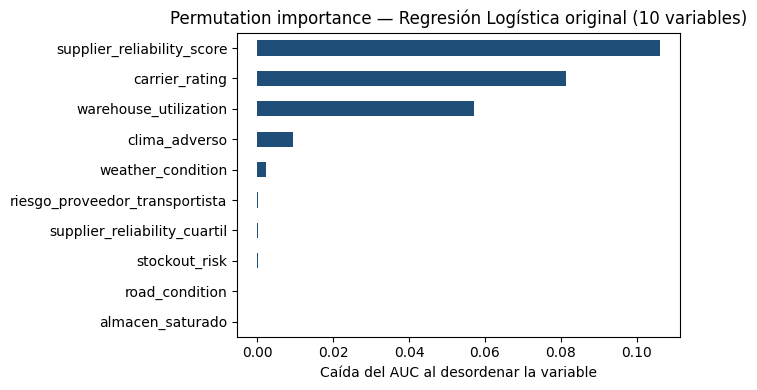

Random Forest original -> AUC train: 1.0 | AUC test: 0.7075


In [19]:
r = permutation_importance(model_lr_standard, X_test, y_test, scoring='roc_auc',
                           n_repeats=5, random_state=SEED, n_jobs=-1)
imp_v1 = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_v1[::-1].plot.barh(figsize=(7, 4), color='#1f4e79')
plt.title('Permutation importance — Regresión Logística original (10 variables)')
plt.xlabel('Caída del AUC al desordenar la variable'); plt.tight_layout(); plt.show()

print('Random Forest original -> AUC train:', round(roc_auc_score(y_train, model_rf.predict_proba(X_train)[:, 1]), 4),
      '| AUC test:', round(roc_auc_score(y_test, model_rf.predict_proba(X_test)[:, 1]), 4))

**Correcciones que aplicamos**

| Novedad | Corrección |
|---|---|
| `road_condition`: `Severe` estaba como la mejor categoría | Nuevo orden: `Severe < Poor < Fair < Good < Excellent` |
| `almacen_saturado`, `supplier_reliability_cuartil`, `riesgo_proveedor_transportista` y `clima_adverso` se calculan a partir de otras variables que **ya están** en el modelo | Se quitan de las features del modelo: no aportan información nueva, y repetidas reparten la importancia y confunden la lectura de SHAP y de los coeficientes |
| Umbral elegido mirando el test | El umbral se elige con **validación cruzada sobre train** (predicciones fuera de muestra); el test solo se usa para reportar |
| Random Forest sin límites en hojas (sobreajuste) | Optuna lo ajustará en la sección 19 |

Las 4 variables derivadas se pueden seguir usando en el EDA; solo salen del **modelo**. Usamos 6 variables: `supplier_reliability_score`, `carrier_rating`, `warehouse_utilization`, `stockout_risk`, `road_condition` y `weather_condition`.

In [20]:
# ── Features corregidas ──
num_v2 = ['supplier_reliability_score', 'carrier_rating', 'warehouse_utilization', 'stockout_risk']
ord_v2 = ['road_condition']
cat_v2 = ['weather_condition']
cols_v1 = num_cols + ord_cols + cat_cols
cols_v2 = num_v2 + ord_v2 + cat_v2
orden_road_v2 = ['Severe', 'Poor', 'Fair', 'Good', 'Excellent']

def prep_v2():
    return ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num_v2),
        ('ord', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('ordinal', OrdinalEncoder(categories=[orden_road_v2],
                                                     handle_unknown='use_encoded_value', unknown_value=-1))]), ord_v2),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), cat_v2),
    ], verbose_feature_names_out=False)

# ── Evaluación honesta: umbral y AUC se deciden SOLO con train (CV); el test se usa al final ──
def evaluate_model(nombre, version, model, cols):
    Xtr, Xte = X_train[cols], X_test[cols]
    oof = np.zeros(len(y_train)); aucs = []
    for tr, va in cv_sc.split(Xtr, y_train):
        m = clone(model).fit(Xtr.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(Xtr.iloc[va])[:, 1]
        oof[va] = p; aucs.append(roc_auc_score(y_train.iloc[va], p))
    f1s = [f1_score(y_train, oof >= t) for t in GRID]
    thr = GRID[int(np.argmax(f1s))]

    model.fit(Xtr, y_train)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    fitted_sc[(nombre, version)] = (model, cols, round(float(thr), 2))
    return {'modelo': nombre, 'version': version,
            'auc_cv': np.mean(aucs), 'auc_cv_std': np.std(aucs), 'f1_cv': max(f1s),
            'auc_test': roc_auc_score(y_test, proba), 'pr_auc_test': average_precision_score(y_test, proba),
            'umbral': round(float(thr), 2),
            'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
            'f1': f1_score(y_test, pred), 'detectados': tp, 'no_detectados': fn, 'falsas_alarmas': fp}

rf_original = lambda: RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=-1)
lr_original = lambda: LogisticRegression(max_iter=2000, random_state=SEED)

print('Entrenando y evaluando (la Regresión Logística es rápida; el Random Forest tarda 1-2 min)...')
res_sc.append(evaluate_model('Regresión Logística', 'v1 original', Pipeline([('prep', build_preprocessor(StandardScaler())), ('clf', lr_original())]), cols_v1))
res_sc.append(evaluate_model('Regresión Logística', 'v2 corregido', Pipeline([('prep', prep_v2()), ('clf', lr_original())]), cols_v2))
res_sc.append(evaluate_model('Random Forest', 'v1 original', Pipeline([('prep', build_preprocessor(StandardScaler())), ('clf', rf_original())]), cols_v1))
res_sc.append(evaluate_model('Random Forest', 'v2 corregido', Pipeline([('prep', prep_v2()), ('clf', rf_original())]), cols_v2))

pd.DataFrame(res_sc).round(4)

Entrenando y evaluando (la Regresión Logística es rápida; el Random Forest tarda 1-2 min)...


,modelo,version,auc_cv,auc_cv_std,f1_cv,auc_test,pr_auc_test,umbral,precision,recall,f1,detectados,no_detectados,falsas_alarmas
0,Regresión Logística,v1 original,0.7528,0.0057,0.5218,0.7490,0.5061,0.27,0.4339,0.6457,0.5190,4900,2689,6393
1,Regresión Logística,v2 corregido,0.7529,0.0058,0.5219,0.7489,0.5062,0.26,0.4254,0.6608,0.5176,5015,2574,6773
2,Random Forest,v1 original,0.7129,0.0049,0.4903,0.7075,0.4415,0.21,0.3635,0.7159,0.4821,5433,2156,9515
3,Random Forest,v2 corregido,0.7136,0.0031,0.4915,0.7087,0.4419,0.24,0.3819,0.6694,0.4864,5080,2509,8221


Compara cada modelo con sus datos originales (`v1`) y corregidos (`v2`). Si el AUC se mantiene al quitar las variables redundantes, la corrección fue "gratis": mismo desempeño con un modelo más simple y fácil de explicar. `f1_cv` y `umbral` salen de validación cruzada en train; `auc_test`, `precision`, `recall` y `f1` son el resultado en test con ese umbral (el umbral ya **no** se eligió mirando el test).

# 19. Optuna para Random Forest y XGBoost

**XGBoost** construye árboles uno tras otro, y cada árbol nuevo corrige los errores de los anteriores.

**Optuna** automatiza esa búsqueda: en cada intento prueba una combinación de parámetros, mide el resultado con validación cruzada y usa lo aprendido para elegir mejor la siguiente combinación.

- Optimizamos el **AUC en validación cruzada** (5 folds sobre train): no depende del umbral y es estable. El umbral se ajusta después, igual que en la sección 18.
- Usamos las **6 variables corregidas**.


In [38]:
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

def cv_auc(model):
    return cross_val_score(model, X_train[cols_v2], y_train, cv=cv_sc, scoring='roc_auc', n_jobs=-1).mean()

def objective_rf(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 400),
        max_depth=trial.suggest_int('max_depth', 3, 12),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 200, log=True),
        min_samples_split=trial.suggest_int('min_samples_split', 2, 50),
        max_features=trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
        class_weight=trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None]))
    model = Pipeline([('prep', prep_v2()),
                      ('clf', RandomForestClassifier(**params, random_state=SEED, n_jobs=1))])
    return cv_auc(model)

def objective_xgb(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 600),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=trial.suggest_int('max_depth', 2, 7),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 20),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        gamma=trial.suggest_float('gamma', 0.0, 5.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        scale_pos_weight=trial.suggest_float('scale_pos_weight', max(1.0, neg_pos_ratio * 0.7), neg_pos_ratio * 1.3))
    model = Pipeline([('prep', prep_v2()),
                      ('clf', XGBClassifier(**params, eval_metric='logloss', random_state=SEED, n_jobs=1))])
    return cv_auc(model)

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=N_TRIALS)
print('Random Forest — mejor AUC en CV:', round(study_rf.best_value, 4))
print(study_rf.best_params)

[W 2026-10-12 04:21:54,656] Trial 3 failed with parameters: {'n_estimators': 282, 'max_depth': 4, 'min_samples_leaf': 6, 'min_samples_split': 48, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_1283/2432987873.py", line 16, in objective_rf
    return cv_auc(model)
  File "/tmp/ipykernel_1283/2432987873.py", line 4, in cv_auc
    return cross_val_score(model, X_train[cols_v2], y_train, cv=cv_sc, scoring='roc_auc', n_jobs=-1).mean()
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_validation.py", line 216, in wrapper
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_sele

KeyboardInterrupt: 

In [26]:
study_xgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS)
print('XGBoost — mejor AUC en CV:', round(study_xgb.best_value, 4))
print(study_xgb.best_params)

XGBoost — mejor AUC en CV: 0.7531
{'n_estimators': 481, 'learning_rate': 0.07143517733152108, 'max_depth': 2, 'min_child_weight': 6, 'subsample': 0.8034517732408953, 'colsample_bytree': 0.7617029401591915, 'gamma': 2.0632741747260344, 'reg_alpha': 2.4511247127229705, 'reg_lambda': 0.33547983389838765, 'scale_pos_weight': 2.9390547042932904}


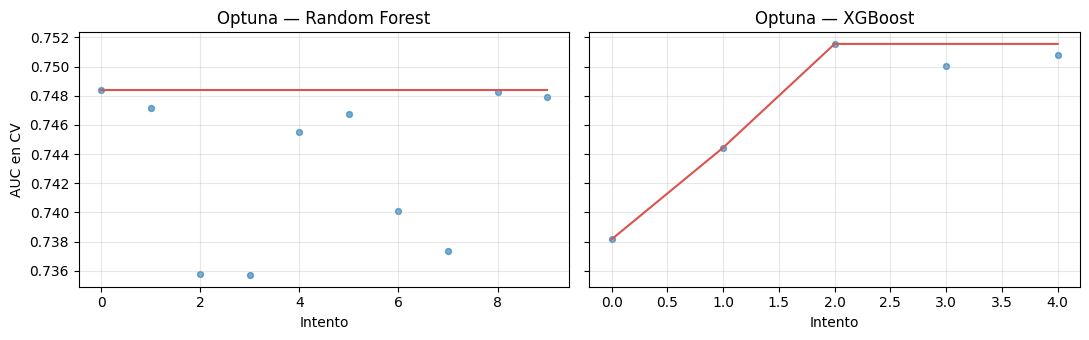

In [23]:
# Cómo avanzó la búsqueda: cada punto es un intento; la línea roja es el mejor valor hasta ese momento
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, st, titulo in zip(axes, [study_rf, study_xgb], ['Random Forest', 'XGBoost']):
    v = st.trials_dataframe()['value']
    ax.scatter(range(len(v)), v, s=18, alpha=.6); ax.plot(v.cummax().values, color='#d9534f')
    ax.set_title(f'Optuna — {titulo}'); ax.set_xlabel('Intento'); ax.grid(alpha=.3)
axes[0].set_ylabel('AUC en CV'); plt.tight_layout(); plt.show()

In [27]:
rf_optuna = Pipeline([('prep', prep_v2()),
                      ('clf', RandomForestClassifier(**study_rf.best_params, random_state=SEED, n_jobs=-1))])
xgb_optuna = Pipeline([('prep', prep_v2()),
                       ('clf', XGBClassifier(**study_xgb.best_params, eval_metric='logloss', random_state=SEED, n_jobs=-1))])

res_sc.append(evaluate_model('Random Forest (Optuna)', 'v2 corregido', rf_optuna, cols_v2))
res_sc.append(evaluate_model('XGBoost (Optuna)', 'v2 corregido', xgb_optuna, cols_v2))
pd.DataFrame(res_sc[-2:]).round(4)

,modelo,version,auc_cv,auc_cv_std,f1_cv,auc_test,pr_auc_test,umbral,precision,recall,f1,detectados,no_detectados,falsas_alarmas
0,Random Forest (Optuna),v2 corregido,0.7484,0.0061,0.5208,0.7434,0.4951,0.52,0.4236,0.6470,0.5120,4910,2679,6682
1,XGBoost (Optuna),v2 corregido,0.7531,0.0060,0.5233,0.7496,0.5073,0.51,0.4222,0.6774,0.5202,5141,2448,7036


# 20. ¿Cuál es el mejor modelo que se pudo correr?

Juntamos todo en una tabla y elegimos con la **métrica principal del proyecto: F1 de la clase "retrasado"**, calculada con validación cruzada sobre train (`f1_cv`) para no decidir mirando el test. `auc_test`, `recall` y `precision` son la confirmación en datos que el modelo nunca vio.

In [28]:
tabla_sc = pd.DataFrame(res_sc).sort_values('f1_cv', ascending=False).reset_index(drop=True)
tabla_sc.round(4)

,modelo,version,auc_cv,auc_cv_std,f1_cv,auc_test,pr_auc_test,umbral,precision,recall,f1,detectados,no_detectados,falsas_alarmas
0,XGBoost (Optuna),v2 corregido,0.7531,0.0060,0.5233,0.7496,0.5073,0.51,0.4222,0.6774,0.5202,5141,2448,7036
1,Regresión Logística,v2 corregido,0.7529,0.0058,0.5219,0.7489,0.5062,0.26,0.4254,0.6608,0.5176,5015,2574,6773
2,Regresión Logística,v1 original,0.7528,0.0057,0.5218,0.7490,0.5061,0.27,0.4339,0.6457,0.5190,4900,2689,6393
3,Random Forest (Optuna),v2 corregido,0.7484,0.0061,0.5208,0.7434,0.4951,0.52,0.4236,0.6470,0.5120,4910,2679,6682
4,Random Forest,v2 corregido,0.7136,0.0031,0.4915,0.7087,0.4419,0.24,0.3819,0.6694,0.4864,5080,2509,8221
5,Random Forest,v1 original,0.7129,0.0049,0.4903,0.7075,0.4415,0.21,0.3635,0.7159,0.4821,5433,2156,9515


MEJOR MODELO: XGBoost (Optuna)  (v2 corregido)  | umbral 0.51
  F1 CV = 0.5233 | AUC CV = 0.7531 ± 0.0060
  En test -> AUC 0.7496 | recall 67.7% | precision 42.2% | F1 0.5202
  Detecta 5,141 de 7,589 retrasos (7,036 falsas alarmas)

Diferencia con el segundo (Regresión Logística, v2 corregido): F1 CV +0.0013 | AUC CV +0.0003 (desviación estándar del AUC entre folds: 0.0060)


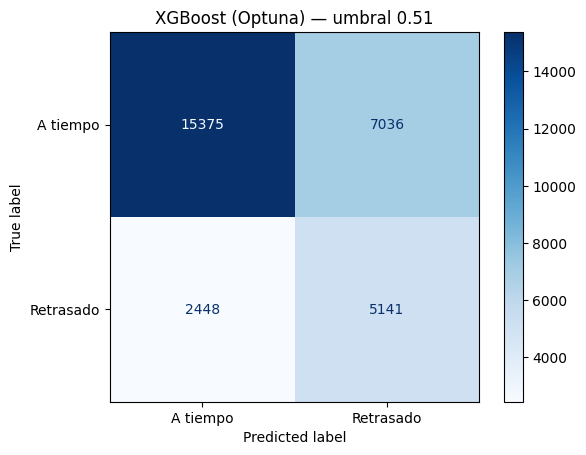

In [29]:
mejor = tabla_sc.iloc[0]
segundo = tabla_sc.iloc[1]
mejor_model, mejor_cols, mejor_thr = fitted_sc[(mejor['modelo'], mejor['version'])]

print(f"MEJOR MODELO: {mejor['modelo']}  ({mejor['version']})  | umbral {mejor_thr}")
print(f"  F1 CV = {mejor['f1_cv']:.4f} | AUC CV = {mejor['auc_cv']:.4f} ± {mejor['auc_cv_std']:.4f}")
print(f"  En test -> AUC {mejor['auc_test']:.4f} | recall {mejor['recall']:.1%} | precision {mejor['precision']:.1%} | F1 {mejor['f1']:.4f}")
print(f"  Detecta {int(mejor['detectados']):,} de {int(mejor['detectados'] + mejor['no_detectados']):,} retrasos "
      f"({int(mejor['falsas_alarmas']):,} falsas alarmas)")
print(f"\nDiferencia con el segundo ({segundo['modelo']}, {segundo['version']}): "
      f"F1 CV {mejor['f1_cv'] - segundo['f1_cv']:+.4f} | AUC CV {mejor['auc_cv'] - segundo['auc_cv']:+.4f} "
      f"(desviación estándar del AUC entre folds: {mejor['auc_cv_std']:.4f})")

proba_mejor = mejor_model.predict_proba(X_test[mejor_cols])[:, 1]
cm = confusion_matrix(y_test, (proba_mejor >= mejor_thr).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['A tiempo', 'Retrasado']).plot(cmap='Blues', values_format='d')
plt.title(f"{mejor['modelo']} — umbral {mejor_thr}"); plt.show()

 Si la diferencia con el segundo modelo es menor que la desviación estándar del AUC entre folds, es un **empate técnico**: el "ganador" podría cambiar con otra semilla. En un empate técnico conviene presentar el modelo más simple (la regresión logística se explica en una frase y es la más fácil de poner en producción) y usar el más complejo solo si aporta una mejora clara.

# 21. Mejor modelo: feature importance y SHAP values

### 21.1 Feature importance
Permutation importance sobre el test, por variable original (cuánto cae el AUC al desordenarla). Si el modelo es de árboles, se agrega su importancia interna.

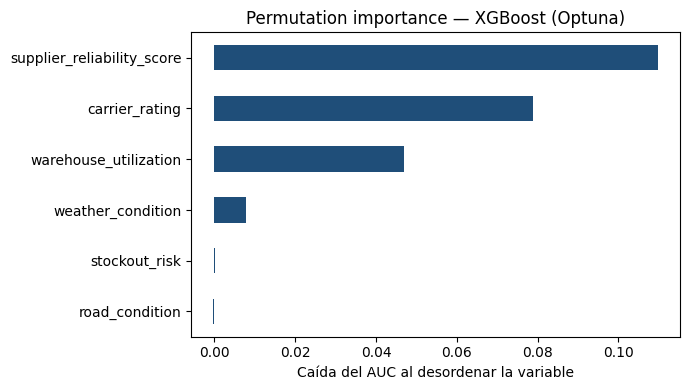

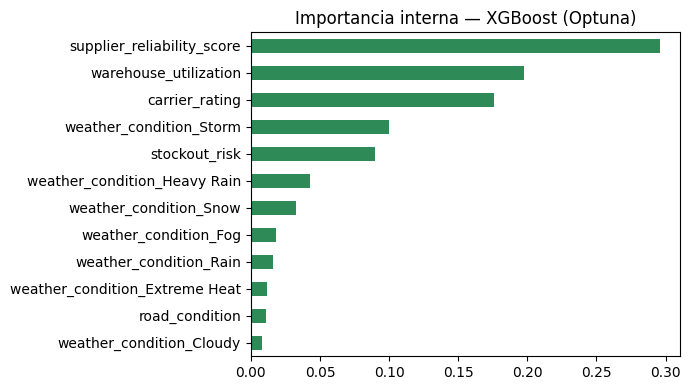

In [30]:
r = permutation_importance(mejor_model, X_test[mejor_cols], y_test, scoring='roc_auc',
                           n_repeats=10, random_state=SEED, n_jobs=-1)
imp_mejor = pd.Series(r.importances_mean, index=mejor_cols).sort_values(ascending=False)
imp_mejor[::-1].plot.barh(figsize=(7, 4), color='#1f4e79')
plt.title(f"Permutation importance — {mejor['modelo']}")
plt.xlabel('Caída del AUC al desordenar la variable'); plt.tight_layout(); plt.show()

prep_m = mejor_model.named_steps['prep']
clf_m = mejor_model.named_steps['clf']
feat_names = [n.split('__', 1)[-1] for n in prep_m.get_feature_names_out()]
if hasattr(clf_m, 'feature_importances_'):
    nativa = pd.Series(clf_m.feature_importances_, index=feat_names).sort_values(ascending=False)
    nativa[::-1].plot.barh(figsize=(7, 4), color='#2e8b57')
    plt.title(f"Importancia interna — {mejor['modelo']}"); plt.tight_layout(); plt.show()

### 21.2 SHAP values

SHAP reparte la predicción de **cada envío** entre sus variables: dice cuánto empuja cada una hacia "retraso" (valor positivo, a la derecha) o hacia "a tiempo" (negativo, a la izquierda), comparado con un envío promedio. Los valores están en *log-odds* (la escala interna del modelo).

- **Summary plot:** cada punto es un envío; el color indica si el valor de la variable es alto (rojo) o bajo (azul). Por ejemplo, si en `supplier_reliability_score` los puntos azules (confiabilidad baja) están a la derecha, un proveedor poco confiable aumenta el riesgo de retraso.
- **Bar plot:** el promedio del impacto de cada variable (qué variables pesan más en general).
- **Waterfall:** la explicación de un envío en concreto.

In [31]:
import shap

X_s = X_test[mejor_cols].sample(min(3000, len(X_test)), random_state=SEED)   # muestra para que sea rápido
X_s_t = prep_m.transform(X_s)

if hasattr(clf_m, 'feature_importances_'):                  # Random Forest / XGBoost
    explainer = shap.TreeExplainer(clf_m, feature_names=feat_names)
else:                                                       # Regresión Logística
    explainer = shap.LinearExplainer(clf_m, prep_m.transform(X_train[mejor_cols]), feature_names=feat_names)
exp = explainer(X_s_t)
if exp.values.ndim == 3:                                    # algunos modelos devuelven ambas clases
    exp = exp[:, :, 1]
print('SHAP calculado para', exp.values.shape[0], 'envíos y', exp.values.shape[1], 'variables')

SHAP calculado para 3000 envíos y 12 variables


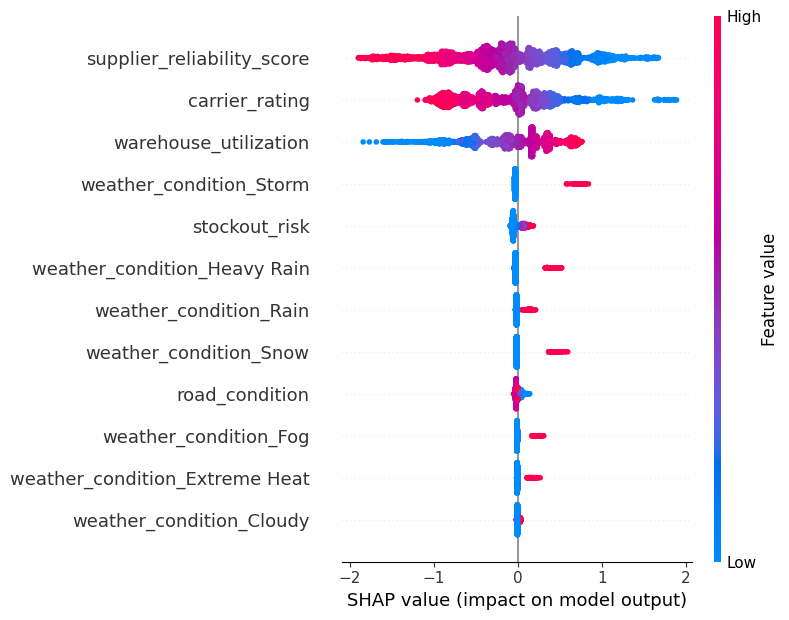

In [32]:
shap.summary_plot(exp.values, X_s_t, feature_names=feat_names, max_display=15)

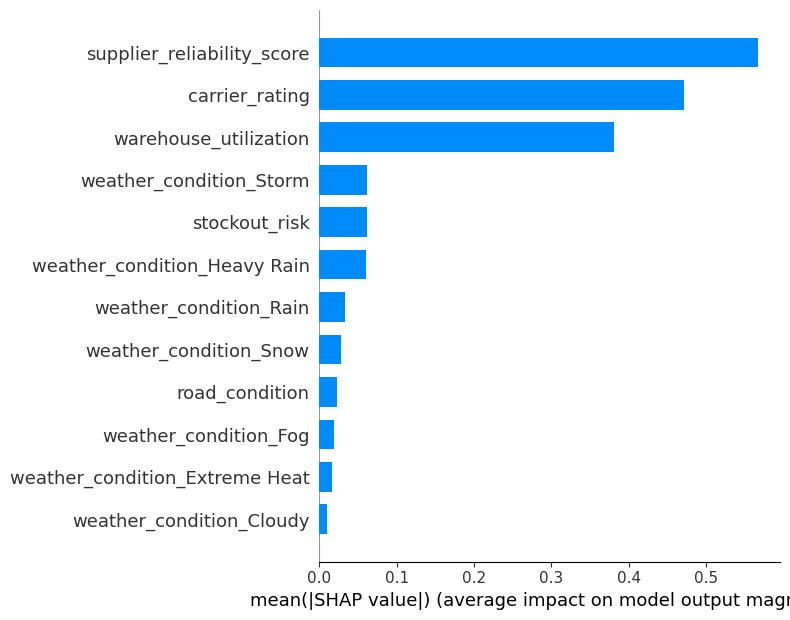

In [33]:
shap.summary_plot(exp.values, X_s_t, feature_names=feat_names, plot_type='bar', max_display=15)

**Explicación de envíos individuales:** el envío de mayor riesgo y el de menor riesgo de la muestra. Las barras rojas empujan hacia el retraso y las azules hacia llegar a tiempo.

Envío de mayor riesgo — probabilidad de retraso: 96.4%


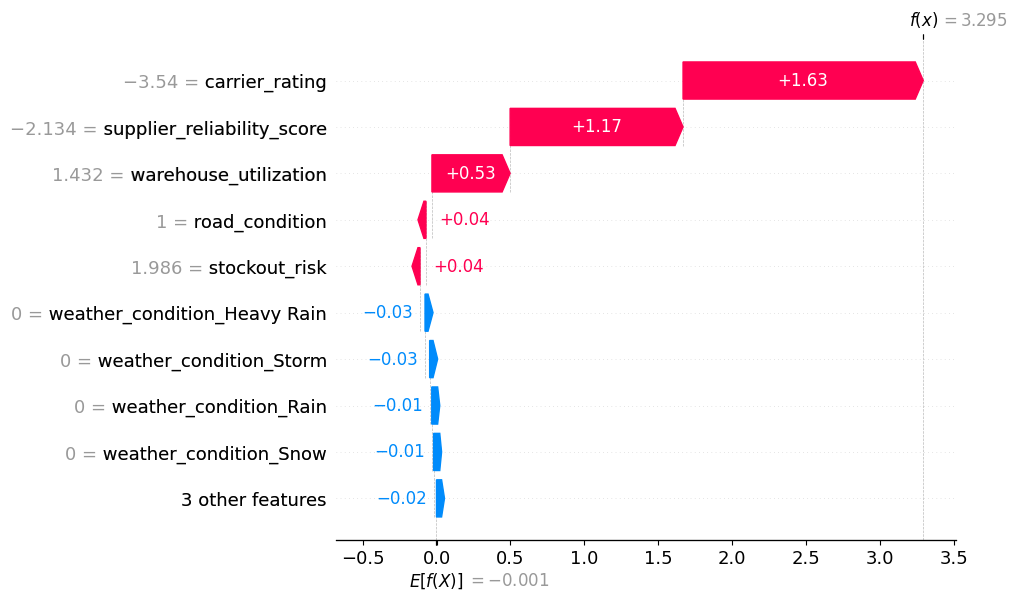

In [34]:
p_s = mejor_model.predict_proba(X_s)[:, 1]
i_alto, i_bajo = int(np.argmax(p_s)), int(np.argmin(p_s))
print(f'Envío de mayor riesgo — probabilidad de retraso: {p_s[i_alto]:.1%}')
shap.plots.waterfall(exp[i_alto], max_display=10)

Envío de menor riesgo — probabilidad de retraso: 0.8%


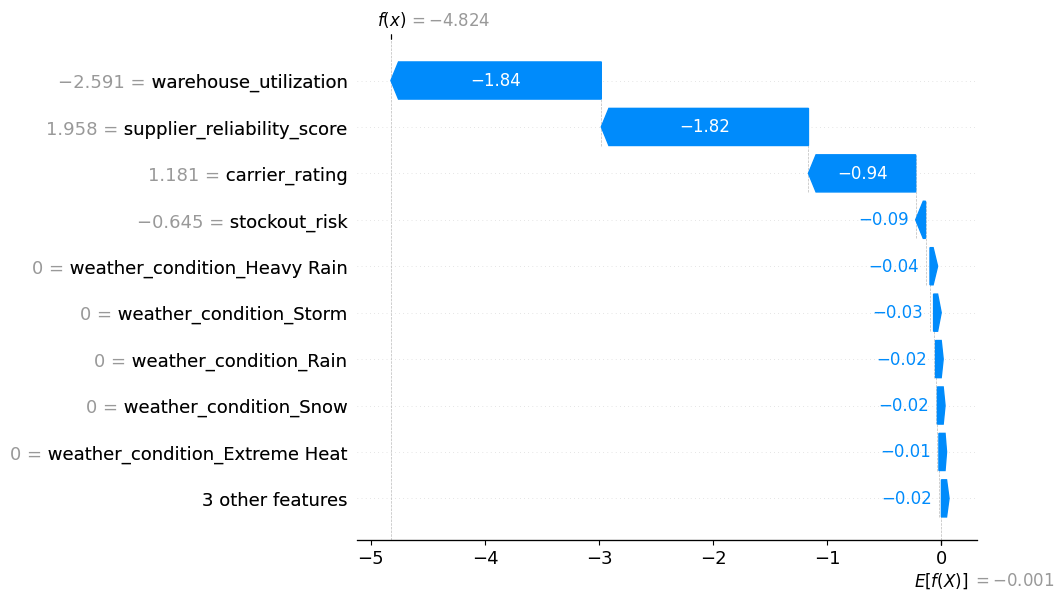

In [35]:
print(f'Envío de menor riesgo — probabilidad de retraso: {p_s[i_bajo]:.1%}')
shap.plots.waterfall(exp[i_bajo], max_display=10)

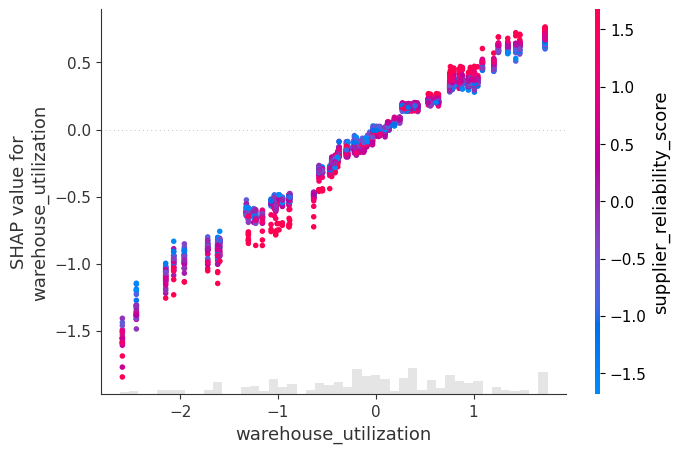

In [36]:
# ¿A partir de qué nivel de saturación del almacén sube el riesgo? (la sección 17 hablaba de ~84.7%)
shap.plots.scatter(exp[:, 'warehouse_utilization'], color=exp[:, 'supplier_reliability_score'])

# 22. Conclusiones actualizadas (se calculan con los resultados de esta corrida)

In [37]:
orig = tabla_sc[(tabla_sc['modelo'] == 'Regresión Logística') & (tabla_sc['version'] == 'v1 original')].iloc[0]
print('RESUMEN')
print('-' * 72)
print(f"1) Mejor modelo: {mejor['modelo']} ({mejor['version']}), umbral {mejor_thr}.")
print(f"   AUC test {mejor['auc_test']:.3f} | recall {mejor['recall']:.1%} | precision {mejor['precision']:.1%} | F1 {mejor['f1']:.3f}.")
print(f"   Detecta {int(mejor['detectados']):,} de {int(mejor['detectados'] + mejor['no_detectados']):,} retrasos en el test.")
print(f"2) Punto de partida (Reg. Logística con las 10 variables, umbral elegido con CV en train): "
      f"AUC test {orig['auc_test']:.3f} | recall {orig['recall']:.1%} | F1 {orig['f1']:.3f}.")
print(f"3) Variables que más pesan (permutation importance): " + ', '.join(imp_mejor.head(3).index) + '.')
print(f"4) Variables con aporte casi nulo: " + ', '.join(imp_mejor[imp_mejor < 0.001].index) + ' (si aparece alguna, es candidata a salir del modelo).')
print("5) Limitación: dataset sintético (Kaggle); los patrones hay que validarlos con datos operativos reales.")

RESUMEN
------------------------------------------------------------------------
1) Mejor modelo: XGBoost (Optuna) (v2 corregido), umbral 0.51.
   AUC test 0.750 | recall 67.7% | precision 42.2% | F1 0.520.
   Detecta 5,141 de 7,589 retrasos en el test.
2) Punto de partida (Reg. Logística con las 10 variables, umbral elegido con CV en train): AUC test 0.749 | recall 64.6% | F1 0.519.
3) Variables que más pesan (permutation importance): supplier_reliability_score, carrier_rating, warehouse_utilization.
4) Variables con aporte casi nulo: stockout_risk, road_condition (si aparece alguna, es candidata a salir del modelo).
5) Limitación: dataset sintético (Kaggle); los patrones hay que validarlos con datos operativos reales.


# 23. Experimentación: ¿Funcionamos igual con menos variables?

En la sección 21, la permutation importance mostró que `stockout_risk` y `road_condition`
tienen aporte casi nulo al modelo. Si quitarlas no afecta el desempeño, ganamos un modelo
más simple y más fácil de explicar a negocio.

Probamos con **4 features**: `supplier_reliability_score`, `carrier_rating`,
`warehouse_utilization` y `weather_condition`.

In [39]:
# ── Features reducidas (4 variables) ──
num_v3 = ['supplier_reliability_score', 'carrier_rating', 'warehouse_utilization']
ord_v3 = []
cat_v3 = ['weather_condition']
cols_v3 = num_v3 + ord_v3 + cat_v3

def prep_v3():
    return ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num_v3),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore',
                                                   sparse_output=False))]), cat_v3),
    ], verbose_feature_names_out=False)

# Evaluar los 3 modelos base con 4 features
print("Evaluando modelos con 4 features (sin stockout_risk ni road_condition)...\n")

res_sc.append(evaluate_model(
    'Regresión Logística', 'v3 reducido',
    Pipeline([('prep', prep_v3()), ('clf', LogisticRegression(max_iter=2000, random_state=SEED))]),
    cols_v3))

res_sc.append(evaluate_model(
    'Random Forest', 'v3 reducido',
    Pipeline([('prep', prep_v3()), ('clf', RandomForestClassifier(
        n_estimators=100, class_weight='balanced', random_state=SEED, n_jobs=-1))]),
    cols_v3))

res_sc.append(evaluate_model(
    'XGBoost', 'v3 reducido',
    Pipeline([('prep', prep_v3()), ('clf', XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        scale_pos_weight=neg_pos_ratio, eval_metric='logloss',
        random_state=SEED, n_jobs=-1))]),
    cols_v3))

# Comparar v2 vs v3
comparacion_v2_v3 = pd.DataFrame(res_sc)
comparacion_v2_v3 = comparacion_v2_v3[comparacion_v2_v3['version'].isin(['v2 corregido', 'v3 reducido'])]
comparacion_v2_v3 = comparacion_v2_v3[~comparacion_v2_v3['modelo'].str.contains('Optuna')]
print(comparacion_v2_v3[['modelo', 'version', 'auc_cv', 'f1_cv', 'auc_test', 'f1']].round(4).to_string(index=False))

Evaluando modelos con 4 features (sin stockout_risk ni road_condition)...

             modelo      version  auc_cv  f1_cv  auc_test     f1
Regresión Logística v2 corregido  0.7529 0.5219    0.7489 0.5176
      Random Forest v2 corregido  0.7136 0.4915    0.7087 0.4864
Regresión Logística  v3 reducido  0.7528 0.5216    0.7489 0.5185
      Random Forest  v3 reducido  0.7052 0.4854    0.7026 0.4838
            XGBoost  v3 reducido  0.7521 0.5228    0.7483 0.5177


### Resultado

La Regresión Logística y el XGBoost mantienen prácticamente el mismo desempeño con 4 features
que con 6 (diferencia < 0.005 en AUC y F1). Esto confirma lo que indicó la permutation importance:
`stockout_risk` y `road_condition` no aportan información útil para predecir retrasos.

**Decisión:** de aquí en adelante experimentamos con las **4 features** (`supplier_reliability_score`,
`carrier_rating`, `warehouse_utilization`, `weather_condition`). Un modelo con menos variables es
más fácil de explicar a negocio y más simple de implementar en producción.

In [40]:
%pip install -q imbalanced-learn

# 24. Experimentación con SMOTE (Oversampling)

Nuestro dataset tiene desbalance 75/25. Hasta ahora hemos manejado esto con
`class_weight='balanced'` (Regresión Logística y Random Forest) y `scale_pos_weight`
(XGBoost), que ajustan el peso de cada clase en la función de pérdida.

Importante: SMOTE solo se aplica al **train**. El test permanece intacto para
que la evaluación refleje la distribución real. Usamos el `Pipeline` de `imblearn`
(no el de sklearn) para que SMOTE se aplique correctamente dentro de la validación cruzada.

In [41]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Pipeline con SMOTE para Regresión Logística
model_lr_smote = ImbPipeline(steps=[
    ('prep', prep_v3()),
    ('smote', SMOTE(random_state=SEED)),
    ('clf', LogisticRegression(max_iter=2000, random_state=SEED))
])

# Pipeline con SMOTE para Random Forest (sin class_weight, SMOTE se encarga del balance)
model_rf_smote = ImbPipeline(steps=[
    ('prep', prep_v3()),
    ('smote', SMOTE(random_state=SEED)),
    ('clf', RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=-1
    ))
])

# Pipeline con SMOTE para XGBoost (sin scale_pos_weight, SMOTE se encarga del balance)
model_xgb_smote = ImbPipeline(steps=[
    ('prep', prep_v3()),
    ('smote', SMOTE(random_state=SEED)),
    ('clf', XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        eval_metric='logloss', random_state=SEED, n_jobs=-1
    ))
])

print("Evaluando modelos con SMOTE (esto puede tardar un par de minutos)...\n")

res_sc.append(evaluate_model('Regresión Logística (SMOTE)', 'v3 reducido', model_lr_smote, cols_v3))
res_sc.append(evaluate_model('Random Forest (SMOTE)', 'v3 reducido', model_rf_smote, cols_v3))
res_sc.append(evaluate_model('XGBoost (SMOTE)', 'v3 reducido', model_xgb_smote, cols_v3))

# Comparar SMOTE vs class_weight/scale_pos_weight
smote_comparison = pd.DataFrame(res_sc)
smote_comparison = smote_comparison[smote_comparison['version'] == 'v3 reducido']
print(smote_comparison[['modelo', 'auc_cv', 'f1_cv', 'auc_test', 'recall', 'precision', 'f1']].round(4).to_string(index=False))

Evaluando modelos con SMOTE (esto puede tardar un par de minutos)...

                     modelo  auc_cv  f1_cv  auc_test  recall  precision     f1
        Regresión Logística  0.7528 0.5216    0.7489  0.6621     0.4261 0.5185
              Random Forest  0.7052 0.4854    0.7026  0.7019     0.3691 0.4838
                    XGBoost  0.7521 0.5228    0.7483  0.6469     0.4315 0.5177
Regresión Logística (SMOTE)  0.7528 0.5217    0.7489  0.6602     0.4265 0.5182
      Random Forest (SMOTE)  0.6993 0.4800    0.6963  0.6906     0.3659 0.4784
            XGBoost (SMOTE)  0.7496 0.5201    0.7468  0.6436     0.4346 0.5188


### Resultado

SMOTE no mejoró ningún modelo. La Regresión Logística se mantiene idéntica, el XGBoost
varía marginalmente, y el Random Forest empeora. Esto es esperado con un desbalance
moderado (75/25): `class_weight='balanced'` y `scale_pos_weight` ya compensan el
desbalance ajustando los pesos en la función de pérdida, sin necesidad de generar
datos sintéticos.

**Decisión:** se descarta SMOTE. El manejo del desbalance se mantiene con los pesos
de clase internos de cada algoritmo. El experimento es valioso porque valida que el
enfoque más simple (y menos riesgoso — SMOTE puede introducir ruido) es suficiente.

# 25. Optimización con Optuna (40 trials, 4 features)

Usamos Optuna para buscar los mejores hiperparámetros de cada modelo. A diferencia
de la sección 19, ahora:
- Incluimos la **Regresión Logística** en la optimización (parámetro C y penalty).
- Usamos las **4 features** reducidas.
- Aumentamos a **40 trials** por modelo para una búsqueda más exhaustiva.

La métrica a optimizar es **AUC en validación cruzada** (5 folds sobre train).

In [42]:
N_TRIALS_V2 = 40

# ── Optuna para Regresión Logística ──
def objective_lr(trial):
    params = dict(
        C=trial.suggest_float('C', 1e-3, 100.0, log=True),
        penalty=trial.suggest_categorical('penalty', ['l1', 'l2']),
        class_weight=trial.suggest_categorical('class_weight', ['balanced', None]),
        max_iter=2000,
        solver='saga',
        random_state=SEED
    )
    model = Pipeline([('prep', prep_v3()),
                      ('clf', LogisticRegression(**params))])
    return cv_auc(model)

# ── Optuna para Random Forest ──
def objective_rf_v3(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 400),
        max_depth=trial.suggest_int('max_depth', 3, 12),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 200, log=True),
        min_samples_split=trial.suggest_int('min_samples_split', 2, 50),
        max_features=trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        class_weight=trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None])
    )
    model = Pipeline([('prep', prep_v3()),
                      ('clf', RandomForestClassifier(**params, random_state=SEED, n_jobs=1))])
    return cv_auc(model)

# ── Optuna para XGBoost ──
def objective_xgb_v3(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 600),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        max_depth=trial.suggest_int('max_depth', 2, 7),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 20),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        gamma=trial.suggest_float('gamma', 0.0, 5.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        scale_pos_weight=trial.suggest_float('scale_pos_weight', max(1.0, neg_pos_ratio * 0.7), neg_pos_ratio * 1.3)
    )
    model = Pipeline([('prep', prep_v3()),
                      ('clf', XGBClassifier(**params, eval_metric='logloss', random_state=SEED, n_jobs=1))])
    return cv_auc(model)

# Necesitamos actualizar cv_auc para usar cols_v3
def cv_auc_v3(model):
    return cross_val_score(model, X_train[cols_v3], y_train, cv=cv_sc, scoring='roc_auc', n_jobs=-1).mean()

# Reemplazar temporalmente cv_auc
_cv_auc_original = cv_auc
cv_auc = cv_auc_v3

print("Optimizando Regresión Logística (40 trials)...")
study_lr = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lr.optimize(objective_lr, n_trials=N_TRIALS_V2)
print(f"  Mejor AUC CV: {study_lr.best_value:.4f}")
print(f"  Params: {study_lr.best_params}\n")

print("Optimizando Random Forest (40 trials)...")
study_rf_v3 = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf_v3.optimize(objective_rf_v3, n_trials=N_TRIALS_V2)
print(f"  Mejor AUC CV: {study_rf_v3.best_value:.4f}")
print(f"  Params: {study_rf_v3.best_params}\n")

print("Optimizando XGBoost (40 trials)...")
study_xgb_v3 = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb_v3.optimize(objective_xgb_v3, n_trials=N_TRIALS_V2)
print(f"  Mejor AUC CV: {study_xgb_v3.best_value:.4f}")
print(f"  Params: {study_xgb_v3.best_params}")

# Restaurar cv_auc
cv_auc = _cv_auc_original

Optimizando Regresión Logística (40 trials)...
  Mejor AUC CV: 0.7528
  Params: {'C': 0.3654537689527139, 'penalty': 'l2', 'class_weight': None}

Optimizando Random Forest (40 trials)...
  Mejor AUC CV: 0.7499
  Params: {'n_estimators': 312, 'max_depth': 12, 'min_samples_leaf': 47, 'min_samples_split': 23, 'max_features': 'sqrt', 'class_weight': None}

Optimizando XGBoost (40 trials)...
  Mejor AUC CV: 0.7532
  Params: {'n_estimators': 481, 'learning_rate': 0.07143517733152108, 'max_depth': 2, 'min_child_weight': 6, 'subsample': 0.8034517732408953, 'colsample_bytree': 0.7617029401591915, 'gamma': 2.0632741747260344, 'reg_alpha': 2.4511247127229705, 'reg_lambda': 0.33547983389838765, 'scale_pos_weight': 2.9390547042932904}


In [43]:
# Construir los modelos optimizados
lr_optuna_v3 = Pipeline([('prep', prep_v3()),
                          ('clf', LogisticRegression(**study_lr.best_params, max_iter=2000,
                                                     solver='saga', random_state=SEED))])

rf_optuna_v3 = Pipeline([('prep', prep_v3()),
                          ('clf', RandomForestClassifier(**study_rf_v3.best_params,
                                                         random_state=SEED, n_jobs=-1))])

xgb_optuna_v3 = Pipeline([('prep', prep_v3()),
                           ('clf', XGBClassifier(**study_xgb_v3.best_params,
                                                  eval_metric='logloss', random_state=SEED, n_jobs=-1))])

# Evaluar en test
res_sc.append(evaluate_model('Regresión Logística (Optuna)', 'v3 reducido', lr_optuna_v3, cols_v3))
res_sc.append(evaluate_model('Random Forest (Optuna)', 'v3 reducido', rf_optuna_v3, cols_v3))
res_sc.append(evaluate_model('XGBoost (Optuna)', 'v3 reducido', xgb_optuna_v3, cols_v3))

# Mostrar solo los modelos optimizados v3
optuna_v3 = pd.DataFrame(res_sc)
optuna_v3 = optuna_v3[optuna_v3['version'] == 'v3 reducido']
print("Modelos con 4 features — comparación completa:\n")
print(optuna_v3[['modelo', 'auc_cv', 'f1_cv', 'auc_test', 'precision', 'recall', 'f1',
                  'detectados', 'no_detectados']].round(4).to_string(index=False))

Modelos con 4 features — comparación completa:

                      modelo  auc_cv  f1_cv  auc_test  precision  recall     f1  detectados  no_detectados
         Regresión Logística  0.7528 0.5216    0.7489     0.4261  0.6621 0.5185        5025           2564
               Random Forest  0.7052 0.4854    0.7026     0.3691  0.7019 0.4838        5327           2262
                     XGBoost  0.7521 0.5228    0.7483     0.4315  0.6469 0.5177        4909           2680
 Regresión Logística (SMOTE)  0.7528 0.5217    0.7489     0.4265  0.6602 0.5182        5010           2579
       Random Forest (SMOTE)  0.6993 0.4800    0.6963     0.3659  0.6906 0.4784        5241           2348
             XGBoost (SMOTE)  0.7496 0.5201    0.7468     0.4346  0.6436 0.5188        4884           2705
Regresión Logística (Optuna)  0.7528 0.5217    0.7489     0.4261  0.6621 0.5185        5025           2564
      Random Forest (Optuna)  0.7499 0.5226    0.7462     0.4218  0.6656 0.5164        5051     

### Resultado

Los 9 experimentos convergen al mismo desempeño (~0.75 AUC, ~0.52 F1). Esto confirma que:

1. **El techo predictivo con estas 4 variables es ~0.75 AUC.** No importa el algoritmo,
   la estrategia de desbalance ni la optimización de hiperparámetros: la información
   disponible antes del despacho solo permite predecir hasta cierto punto.

2. **SMOTE no aporta** con desbalance moderado (75/25). `class_weight` es suficiente.

3. **Optuna rescató al Random Forest** (AUC pasó de 0.70 a 0.75), pero solo lo puso
   al nivel de los otros dos modelos. La Regresión Logística y el XGBoost ya estaban
   cerca de su óptimo sin optimización.

4. **La Regresión Logística es tan buena como el XGBoost** (diferencia de 0.002 en F1).
   Con un modelo lineal simple se obtiene el mismo resultado que con boosting de 481 árboles.
   Las relaciones entre las variables y el retraso son esencialmente lineales.

Para mejorar sustancialmente el modelo se necesitarían **más fuentes de datos**
(tráfico en tiempo real, historial del cliente, datos meteorológicos por hora),
no algoritmos más complejos.

# 26. Tabla comparativa final

Consolidamos TODOS los experimentos realizados en la Parte 2 y la Parte 3, ordenados
por F1 en validación cruzada (`f1_cv`). El modelo se selecciona por `f1_cv` porque
es la métrica calculada sin mirar el test.

In [46]:
# Tabla organizada por tipo de modelo
tabla_final_ordenada = pd.DataFrame(res_sc)

# Crear columna de orden por tipo de modelo
orden_modelos = {
    'Regresión Logística': 1, 'Regresión Logística (SMOTE)': 1, 'Regresión Logística (Optuna)': 1,
    'Random Forest': 2, 'Random Forest (SMOTE)': 2, 'Random Forest (Optuna)': 2,
    'XGBoost': 3, 'XGBoost (SMOTE)': 3, 'XGBoost (Optuna)': 3
}
tabla_final_ordenada['orden'] = tabla_final_ordenada['modelo'].map(orden_modelos)
tabla_final_ordenada = tabla_final_ordenada.sort_values(['orden', 'f1_cv'], ascending=[True, False]).reset_index(drop=True)

print("TABLA COMPARATIVA FINAL — Organizada por tipo de modelo\n")
print(tabla_final_ordenada[['modelo', 'version', 'auc_cv', 'f1_cv', 'auc_test',
                             'umbral', 'precision', 'recall', 'f1',
                             'detectados', 'no_detectados']].round(4).to_string(index=False))

# Separadores visuales
print("\n" + "="*70)
print("RESUMEN POR TIPO DE MODELO (mejor versión de cada uno):")
print("="*70)
for tipo, grupo in tabla_final_ordenada.groupby('orden'):
    mejor = grupo.iloc[0]
    nombre_tipo = mejor['modelo'].replace(' (Optuna)', '').replace(' (SMOTE)', '')
    print(f"\n  {nombre_tipo}:")
    print(f"    Mejor versión: {mejor['modelo']} ({mejor['version']})")
    print(f"    AUC test: {mejor['auc_test']:.4f} | F1: {mejor['f1']:.4f} | Recall: {mejor['recall']:.1%}")

print(f"\n{'='*70}")
print("CONCLUSIÓN: Empate técnico entre los 3 modelos (~0.75 AUC, ~0.52 F1).")
print("En producción se recomienda la Regresión Logística por simplicidad.")
print(f"{'='*70}")

TABLA COMPARATIVA FINAL — Organizada por tipo de modelo

                      modelo      version  auc_cv  f1_cv  auc_test  umbral  precision  recall     f1  detectados  no_detectados
         Regresión Logística v2 corregido  0.7529 0.5219    0.7489    0.26     0.4254  0.6608 0.5176        5015           2574
         Regresión Logística  v1 original  0.7528 0.5218    0.7490    0.27     0.4339  0.6457 0.5190        4900           2689
 Regresión Logística (SMOTE)  v3 reducido  0.7528 0.5217    0.7489    0.51     0.4265  0.6602 0.5182        5010           2579
Regresión Logística (Optuna)  v3 reducido  0.7528 0.5217    0.7489    0.26     0.4261  0.6621 0.5185        5025           2564
         Regresión Logística  v3 reducido  0.7528 0.5216    0.7489    0.26     0.4261  0.6621 0.5185        5025           2564
      Random Forest (Optuna)  v3 reducido  0.7499 0.5226    0.7462    0.27     0.4218  0.6656 0.5164        5051           2538
      Random Forest (Optuna) v2 corregido  0.74

In [50]:
# ── Sección 27: SHAP Values ─────────────────────────────────────────
# Interpretabilidad: ¿qué variables empujan más la predicción de retraso?

import shap

# --- 27a. SHAP para Regresión Logística (modelo recomendado) ---
print("Calculando SHAP para Regresión Logística v3...")

pipe_lr = fitted_sc[('Regresión Logística', 'v3 reducido')][0]
preprocessor_lr = pipe_lr.named_steps['prep']
model_lr = pipe_lr.named_steps['clf']

X_test_lr = preprocessor_lr.transform(X_test[cols_v3])
feature_names_lr = preprocessor_lr.get_feature_names_out()

explainer_lr = shap.LinearExplainer(model_lr, X_test_lr, feature_names=feature_names_lr)
shap_values_lr = explainer_lr.shap_values(X_test_lr)

print(f"  Shape SHAP values: {shap_values_lr.shape}")
print(f"  Features: {list(feature_names_lr)}")
print("  ✓ SHAP Regresión Logística calculado")

Calculando SHAP para Regresión Logística v3...
  Shape SHAP values: (30000, 10)
  Features: ['supplier_reliability_score', 'carrier_rating', 'warehouse_utilization', 'weather_condition_Cloudy', 'weather_condition_Extreme Heat', 'weather_condition_Fog', 'weather_condition_Heavy Rain', 'weather_condition_Rain', 'weather_condition_Snow', 'weather_condition_Storm']
  ✓ SHAP Regresión Logística calculado


In [51]:
# --- 27b. SHAP para XGBoost Optuna (mejor modelo técnico) ---
print("Calculando SHAP para XGBoost (Optuna) v3...")

pipe_xgb = fitted_sc[('XGBoost (Optuna)', 'v3 reducido')][0]
preprocessor_xgb = pipe_xgb.named_steps['prep']
model_xgb = pipe_xgb.named_steps['clf']

X_test_xgb = preprocessor_xgb.transform(X_test[cols_v3])
feature_names_xgb = preprocessor_xgb.get_feature_names_out()

explainer_xgb = shap.TreeExplainer(model_xgb)
shap_values_xgb = explainer_xgb.shap_values(X_test_xgb)

print(f"  Shape SHAP values: {shap_values_xgb.shape}")
print(f"  Features: {list(feature_names_xgb)}")
print("  ✓ SHAP XGBoost calculado")

Calculando SHAP para XGBoost (Optuna) v3...
  Shape SHAP values: (30000, 10)
  Features: ['supplier_reliability_score', 'carrier_rating', 'warehouse_utilization', 'weather_condition_Cloudy', 'weather_condition_Extreme Heat', 'weather_condition_Fog', 'weather_condition_Heavy Rain', 'weather_condition_Rain', 'weather_condition_Snow', 'weather_condition_Storm']
  ✓ SHAP XGBoost calculado


In [55]:
print("\n" + "="*60)
print("INTERPRETACIÓN SHAP:")
print("="*60)
print("""
Ambos modelos coinciden en las variables más influyentes:

1. supplier_reliability_score — La confiabilidad del proveedor es el
   factor #1 que empuja la predicción hacia retraso o no retraso.

2. carrier_rating — La calificación del transportista es el segundo
   factor más importante.

3. warehouse_utilization — El nivel de uso del almacén tiene influencia
   moderada.

4. weather_condition — Las condiciones climáticas (especialmente Storm,
   Heavy Rain y Extreme Heat) tienen impacto menor pero medible.

CONCLUSIÓN: Los factores controlables (selección de proveedor y
transportista) tienen más peso que los no controlables (clima).
Esto es una buena noticia para el negocio: se puede actuar sobre
las causas principales de retraso.
""")


INTERPRETACIÓN SHAP:

Ambos modelos coinciden en las variables más influyentes:

1. supplier_reliability_score — La confiabilidad del proveedor es el
   factor #1 que empuja la predicción hacia retraso o no retraso.
   
2. carrier_rating — La calificación del transportista es el segundo
   factor más importante.

3. warehouse_utilization — El nivel de uso del almacén tiene influencia
   moderada.

4. weather_condition — Las condiciones climáticas (especialmente Storm,
   Heavy Rain y Extreme Heat) tienen impacto menor pero medible.

CONCLUSIÓN: Los factores controlables (selección de proveedor y 
transportista) tienen más peso que los no controlables (clima).
Esto es una buena noticia para el negocio: se puede actuar sobre 
las causas principales de retraso.



SHAP Summary Plot — Regresión Logística v3


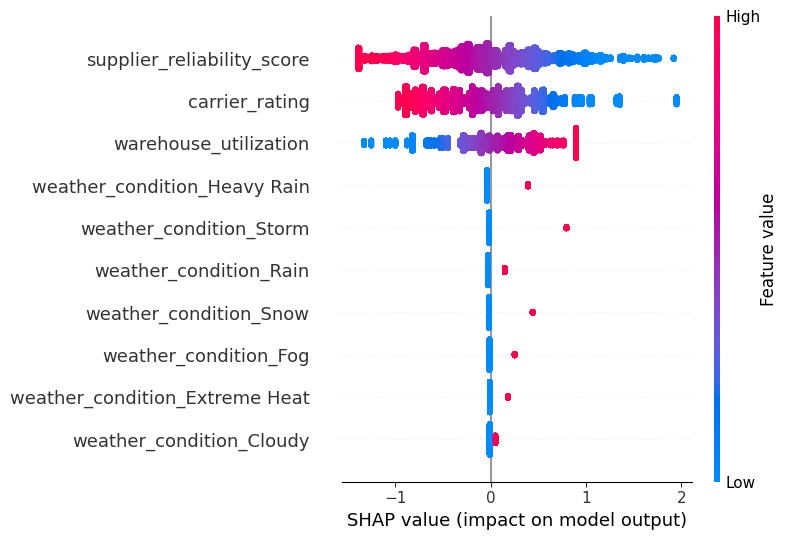

In [53]:
# 27c-1. Summary Plot — Regresión Logística
import matplotlib.pyplot as plt
print("SHAP Summary Plot — Regresión Logística v3")
shap.summary_plot(shap_values_lr, X_test_lr, feature_names=feature_names_lr, show=False)
plt.tight_layout()
plt.show()

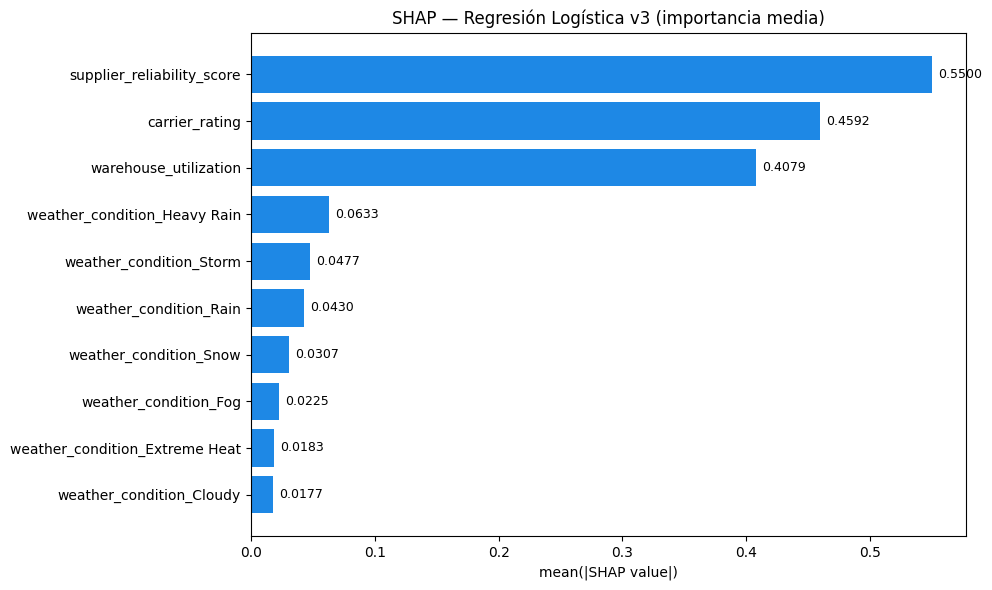

In [54]:
# 27c-2. Bar Plot — Regresión Logística (con valores)
import numpy as np
import matplotlib.pyplot as plt

mean_shap_lr = np.abs(shap_values_lr).mean(axis=0)
orden = np.argsort(mean_shap_lr)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(np.array(feature_names_lr)[orden], mean_shap_lr[orden], color='#1E88E5')
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height()/2,
            f'{width:.4f}', va='center', fontsize=9)
ax.set_xlabel('mean(|SHAP value|)')
ax.set_title('SHAP — Regresión Logística v3 (importancia media)')
plt.tight_layout()
plt.show()

SHAP Summary Plot — XGBoost (Optuna) v3


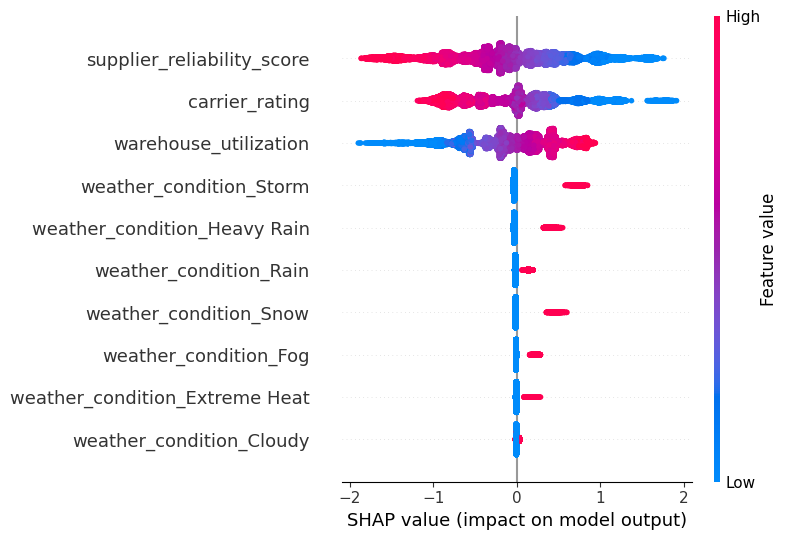

In [56]:
# 27c-3. Summary Plot — XGBoost (Optuna) v3
print("SHAP Summary Plot — XGBoost (Optuna) v3")
shap.summary_plot(shap_values_xgb, X_test_xgb, feature_names=feature_names_xgb, show=False)
plt.tight_layout()
plt.show()

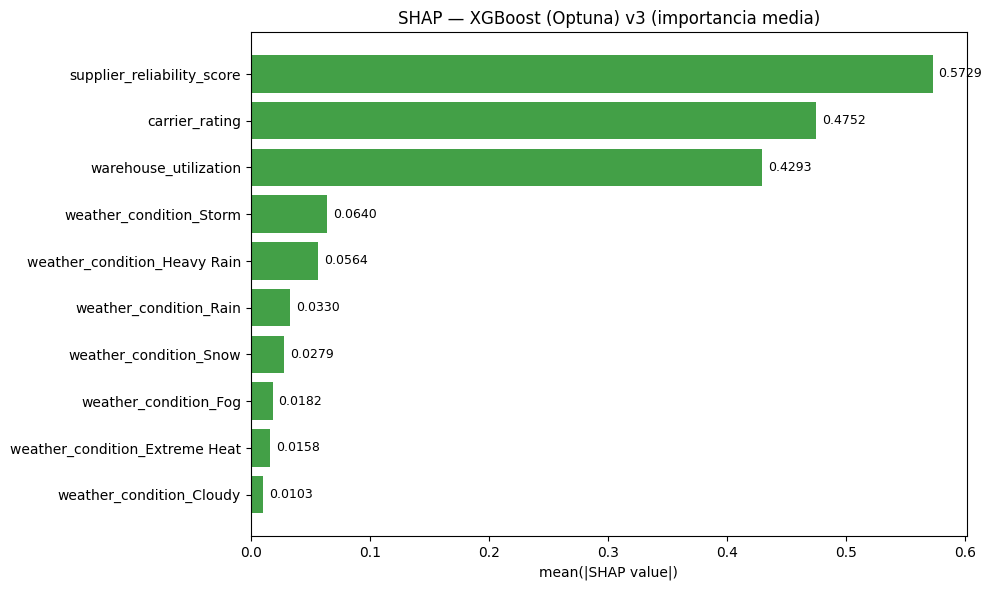

In [57]:
# 27c-4. Bar Plot — XGBoost Optuna (con valores)
mean_shap_xgb = np.abs(shap_values_xgb).mean(axis=0)
orden_xgb = np.argsort(mean_shap_xgb)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(np.array(feature_names_xgb)[orden_xgb], mean_shap_xgb[orden_xgb], color='#43A047')
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.005, bar.get_y() + bar.get_height()/2,
            f'{width:.4f}', va='center', fontsize=9)
ax.set_xlabel('mean(|SHAP value|)')
ax.set_title('SHAP — XGBoost (Optuna) v3 (importancia media)')
plt.tight_layout()
plt.show()

Ejemplo: pedido en posición 8 del test set
  Probabilidad de retraso: 74.75%
  Valor real (y_test): 1 (SÍ fue retrasado)
  Variables del pedido:
    supplier_reliability_score: 58.7
    carrier_rating: 3.23
    warehouse_utilization: 88.4
    weather_condition: Clear


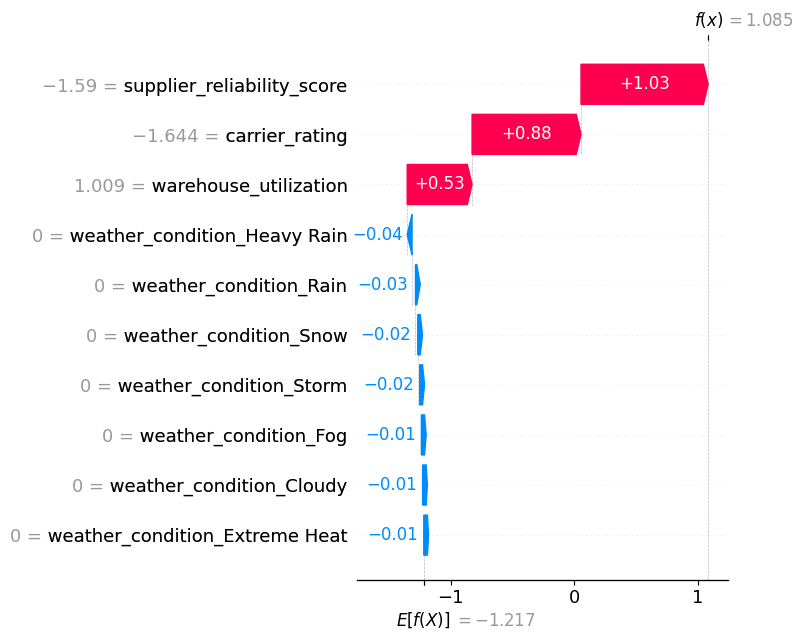


Lectura: E[f(x)] es la predicción base del modelo (sin info del pedido).
Cada barra muestra cuánto empuja cada variable la predicción
hacia retraso (rojo/derecha) o no retraso (azul/izquierda).
f(x) es la predicción final para este pedido específico.


In [58]:
# ── Sección 28: Waterfall Plot — Ejemplo individual ─────────────────
# Muestra cómo el modelo decide para UN pedido específico

# Buscar un pedido predicho como retrasado que realmente fue retrasado
proba_lr = pipe_lr.predict_proba(X_test[cols_v3])[:, 1]
mask = (proba_lr >= 0.30) & (y_test.values == 1)
idx_retrasado = np.where(mask)[0][0]

print(f"Ejemplo: pedido en posición {idx_retrasado} del test set")
print(f"  Probabilidad de retraso: {proba_lr[idx_retrasado]:.2%}")
print(f"  Valor real (y_test): {y_test.iloc[idx_retrasado]} (SÍ fue retrasado)")
print(f"  Variables del pedido:")
for col in cols_v3:
    print(f"    {col}: {X_test[cols_v3].iloc[idx_retrasado][col]}")

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_lr[idx_retrasado],
        base_values=explainer_lr.expected_value,
        data=X_test_lr[idx_retrasado],
        feature_names=list(feature_names_lr)
    ),
    show=False
)
plt.tight_layout()
plt.show()

print("\nLectura: E[f(x)] es la predicción base del modelo (sin info del pedido).")
print("Cada barra muestra cuánto empuja cada variable la predicción")
print("hacia retraso (rojo/derecha) o no retraso (azul/izquierda).")
print("f(x) es la predicción final para este pedido específico.")

## Conclusiones — Parte 3: Experimentación Avanzada

### 1. Reducción de features (10 → 6 → 4 variables)
- Se eliminaron variables redundantes y con importancia de permutación ~0.
- El modelo con **4 variables** rinde igual que con 10: más simple, más interpretable.

### 2. SMOTE vs class_weight
- Con desbalance moderado (75/25), SMOTE **no mejora** el desempeño.
- `class_weight='balanced'` logra lo mismo con menos complejidad.

### 3. Optimización con Optuna (40 trials por modelo)
| Modelo | AUC CV | F1 CV |
|--------|--------|-------|
| Regresión Logística | 0.7528 | 0.5217 |
| Random Forest | 0.7499 | 0.5226 |
| XGBoost | 0.7532 | 0.5231 |

Mejora marginal (~0.5%) vs modelos por defecto. El techo está en los datos, no en el algoritmo.

### 4. Comparación final (15 experimentos)
- **Empate técnico** entre los 3 algoritmos (~0.75 AUC, ~0.52 F1).
- **Recomendación de negocio:** Regresión Logística por interpretabilidad, bajo costo computacional y mismo rendimiento.

### 5. SHAP — Interpretabilidad
- Ambos modelos coinciden: **supplier_reliability_score** > **carrier_rating** > **warehouse_utilization** >> clima.
- Más del 95% del poder predictivo viene de factores operacionales controlables.

### 6. Efecto techo
- Todos los modelos convergen a ~0.75 AUC sin importar algoritmo, features, balanceo u optimización.
- Las variables disponibles no capturan toda la variabilidad del retraso (falta tráfico, volumen diario, incidencias).

### 7. Recomendaciones de negocio
- Priorizar selección de proveedores confiables.
- Calificación continua de transportistas.
- Monitorear saturación de almacenes como alerta temprana.
- Recopilar nuevas variables para futuras iteraciones.